# Das Hubble-Diagramm

Das Notebook rechnet mit den 1701 Lichtkurven von Supernovae vom Typ Ia aus Pantheon+ und den Cepheiden-Entfernungen von SH0ES die absolute Helligkeit der Supernovae, den Achsenabschnitt des Hubble-Flusses und daraus H₀, alles mit der vollen Kovarianzmatrix aus statistischen und systematischen Fehlern. Aus dem ganzen Diagramm bis z = 2.3 folgen Ω_m im flachen ΛCDM und die Ebene Ω_m gegen Ω_Λ mit Krümmung; verglichen wird mit Riess et al. (2022), Brout et al. (2022) und Planck 2018.

Wie schnell dehnt sich das Universum heute aus, gemessen mit explodierenden Sternen, und warum passt die Antwort nicht zu der aus der Hintergrundstrahlung?

#### **Hintergrund**

1929 trug Edwin Hubble die Entfernungen von 24 Galaxien gegen ihre Fluchtgeschwindigkeiten auf und fand eine Gerade: Je weiter eine Galaxie entfernt ist, desto schneller entfernt sie sich. Die Steigung, die Hubble-Konstante H₀, gibt an, wie schnell sich das Universum heute ausdehnt, und ihr Kehrwert ist ungefähr sein Alter. Hubbles eigener Wert war 500 km/s/Mpc, siebenmal zu groß, weil seine Entfernungen falsch geeicht waren. Jahrzehntelang stritten Astronomen dann, ob H₀ eher 50 oder 100 sei, bis das Key Project des Hubble-Weltraumteleskops 2001 72 ± 8 km/s/Mpc fand.

Der Durchbruch kam mit Supernovae vom Typ Ia, Explosionen Weißer Zwerge, die nach einer Korrektur für die Form ihrer Lichtkurve fast gleich hell sind. 1998 fanden zwei Gruppen damit, dass ferne Supernovae schwächer sind als erwartet: Die Expansion beschleunigt sich (Nobelpreis 2011 für Perlmutter, Schmidt und Riess). Heute ist das Hubble-Diagramm aus Supernovae eine der drei Säulen der Kosmologie, neben der Hintergrundstrahlung und den baryonischen akustischen Oszillationen.

Seit etwa 2016 gibt es ein neues Problem: H₀ aus der Entfernungsleiter (Parallaxen, Cepheiden, Supernovae) ist 73 km/s/Mpc, H₀ aus der Hintergrundstrahlung mit dem Standardmodell ΛCDM 67.4 km/s/Mpc, und beide Fehler sind inzwischen klein genug, dass der Unterschied 5σ beträgt. Diese **Hubble-Spannung** ist eines der großen offenen Probleme der Kosmologie: Entweder steckt ein unbekannter Fehler in einer der Messungen, oder ΛCDM fehlt etwas. Dieses Notebook misst H₀ und Ω_m mit den öffentlichen Daten von Pantheon+ und SH0ES selbst nach und sieht sich an, wie fest die Zahl ist.

<a id="landkarte"></a>Landkarte:

- **Daten**
  - [Der Katalog (Schritt 1)](#exp-1): 1701 Lichtkurven von 1543 Supernovae bis z = 2.26; 77 Kalibrator-Lichtkurven, 277 im Hubble-Fluss.
  - [Das Hubble-Diagramm (Schritt 2)](#exp-2): Bei z = 0.4 bis 0.8 sind die Supernovae 0.07 mag schwächer als in einem leeren Universum.
- **Reduktion**
  - [Rotverschiebungen und Eigenbewegungen (Schritt 3)](#exp-3): Unter z = 0.01 macht die Eigenbewegung im Median 0.12 mag aus, im Hubble-Fluss 0.02 mag.
  - [Die Kovarianzmatrix (Schritt 4)](#exp-4): Lichtkurven derselben Supernova korrelieren zu 41 %; die gemeinsamen Fehler machen den Mittelwert um 11 % unsicherer.
- **Eigene Messung**
  - [Die Kalibratoren: wie hell ist eine Supernova? (Schritt 5)](#exp-5): M_B = −19.249 ± 0.030 aus 43 Supernovae mit Cepheiden.
  - [Der Hubble-Fluss (Schritt 6)](#exp-6): Achsenabschnitt a_B = 0.7160 ± 0.0018, damit H₀ = 73.5 ± 1.1 km/s/Mpc.
  - [H₀ im gemeinsamen Fit (Schritt 7)](#exp-7): H₀ = 73.43 ± 1.05 km/s/Mpc mit voller Kovarianz.
- **Modell und Fit**
  - [Ω_m aus dem ganzen Diagramm (Schritt 8)](#exp-8): Ω_m = 0.333 ± 0.018 im flachen ΛCDM; ein Universum nur aus Materie ist um Δχ² = 693 schlechter.
  - [Beschleunigt die Expansion? (Schritt 9)](#exp-9): Ohne Annahme der Flachheit ist Ω_Λ = 0 mit Δχ² = 49 ausgeschlossen, etwa 7σ.
  - [Diagonale gegen volle Kovarianz (Schritt 10)](#exp-10): Ohne Korrelationen wird Ω_m 0.350 statt 0.333, und der Fehler von H₀ schrumpft scheinbar um ein Drittel.
- **Eigene Messung gegen den Katalog**
  - [H₀ gegen SH0ES und Planck: die Hubble-Spannung (Schritt 11)](#exp-11): 0.3σ von SH0ES, 5.2σ von Planck; keine Annahme verschiebt H₀ um mehr als 0.4 km/s/Mpc.
  - [Ω_m gegen Pantheon+ und Planck (Schritt 12)](#exp-12): 0.333 gegen 0.334 (Brout) und 0.315 (Planck), 0.9σ; hier gibt es keine Spannung.

Verwandte Notebooks: eine andere Sprosse der Entfernungsleiter, die Leuchtkraftfunktion Planetarischer Nebel und die Entfernung von M 31 im Vergleich mit Cepheiden, in [Planetarische Nebel](https://github.com/deltorobarba/science/blob/main/astro/nebulae_planetary.ipynb); Leuchtkraftentfernungen aus Gravitationswellen, mit denen sich H₀ ohne Entfernungsleiter messen lässt, in [Der Katalog der Gravitationswellen-Ereignisse](https://github.com/deltorobarba/science/blob/main/astro/gw_catalog.ipynb); ob eine große Leere um uns die Hubble-Spannung erklärt, mit denselben Daten, in [Eine lokale Leere?](https://github.com/deltorobarba/science/blob/main/astro/cosmology_localvoid.ipynb); H₀ von der frühen Seite, aus dem Winkel des Schallhorizonts in der Hintergrundstrahlung, in [Die akustischen Peaks](https://github.com/deltorobarba/science/blob/main/astro/cosmology_cmbpeaks.ipynb); dieselben Supernovae zusammen mit den BAO von DESI und die inverse Entfernungsleiter in [Baryonische akustische Oszillationen](https://github.com/deltorobarba/science/blob/main/astro/cosmology_bao.ipynb); die Supernovae mit kosmischen Chronometern statt Cepheiden geeicht in [Kosmische Chronometer](https://github.com/deltorobarba/science/blob/main/astro/cosmology_chronometers.ipynb).

#### **Theorie**

##### *1. Expansion und Rotverschiebung*

In einem homogenen, expandierenden Universum wachsen alle Abstände mit dem Skalenfaktor a(t). Licht, das unterwegs ist, wird mitgedehnt: Die Rotverschiebung ist $1 + z = a(t_0)/a(t_e)$. Für kleine Entfernungen gilt das **Hubble-Gesetz**

$$cz \approx H_0\, d, \qquad H_0 = \frac{\dot a}{a}\Big|_{t_0}.$$

H₀ wird in km/s pro Megaparsec angegeben; 70 km/s/Mpc heißt, eine Galaxie in 100 Mpc entfernt sich mit 7000 km/s. Dazu kommt die **Eigenbewegung** jeder Galaxie (einige hundert km/s), die bei kleinem z einen großen Teil von cz ausmacht; erst ab etwa z = 0.02 ist sie kleiner als 5 % (Schritt 3).

##### *2. Leuchtkraftentfernung in ΛCDM*

Wie schnell sich das Universum zu jeder Zeit ausdehnt, sagt die Friedmann-Gleichung:

$$E(z)^2 = \frac{H(z)^2}{H_0^2} = \Omega_m (1+z)^3 + \Omega_k (1+z)^2 + \Omega_\Lambda, \qquad \Omega_k = 1 - \Omega_m - \Omega_\Lambda .$$

Die mitbewegte Entfernung ist $D_C = \frac{c}{H_0}\int_0^z \frac{dz'}{E(z')}$; ist der Raum gekrümmt, wird daraus $D_M = \frac{c}{H_0}\frac{\sinh(\sqrt{\Omega_k} H_0 D_C/c)}{\sqrt{\Omega_k}}$ (für $\Omega_k < 0$ mit sin). Die **Leuchtkraftentfernung**, mit der der Fluss wie $L/(4\pi d_L^2)$ abfällt, ist

$$d_L = (1 + z_\text{hel})\, D_M(z), \qquad \mu = m - M = 5\log_{10}\frac{d_L}{10\ \text{pc}} .$$

Für kleine z hilft eine Reihe mit dem Bremsparameter $q_0 = \Omega_m/2 - \Omega_\Lambda$ und dem Ruck $j_0$:

$$d_L \approx \frac{cz}{H_0}\left[1 + \tfrac12(1-q_0)z - \tfrac16(1 - q_0 - 3q_0^2 + j_0)z^2\right].$$

Ist $q_0 < 0$, beschleunigt die Expansion; ferne Objekte sind dann weiter weg und schwächer, als es ohne Beschleunigung wäre.

##### *3. Supernovae als Standardkerzen*

Eine Supernova vom Typ Ia erreicht im Maximum etwa $M_B \approx -19.3$. Die Helligkeiten streuen von Natur aus um 0.3 bis 0.4 mag, aber hellere Supernovae haben breitere Lichtkurven und blauere Farben. Die **Tripp-Formel** standardisiert:

$$m_\text{corr} = m_B + \alpha x_1 - \beta c + \Delta_\text{Wirt} + \Delta_\text{Auswahl},$$

mit Breite $x_1$, Farbe $c$ ($\alpha \approx 0.15$, $\beta \approx 3$), einer Stufe nach der Masse der Wirtsgalaxie und einer Korrektur für Auswahleffekte. Danach streuen sie nur noch um gut 0.1 mag. Pantheon+ gibt $m_\text{corr}$ als `m_b_corr` an; das Modell für jede Lichtkurve ist $m_\text{corr} = M_B + \mu$.

##### *4. Die Entfernungsleiter*

$M_B$ ist nicht aus der Physik bekannt, man muss es eichen. Parallaxen (Gaia, HST) geben die Leuchtkraft von Cepheiden in der Milchstraße; Cepheiden in den etwa 40 Galaxien, in denen eine Supernova explodiert ist, geben deren Entfernungsmodul $\mu_\text{Ceph}$, und damit ist $M_B = m_\text{corr} - \mu_\text{Ceph}$. Im Hubble-Fluss misst man den Achsenabschnitt

$$a_B = \log_{10}\!\left(cz\left[1 + \tfrac12(1-q_0)z - \ldots\right]\right) - 0.2\, m_\text{corr},$$

der nicht von H₀ abhängt, und erhält (Riess et al. 2016)

$$\log_{10} H_0 = 0.2\, M_B + a_B + 5 .$$

Ein Fehler von 0.1 mag in $M_B$ ist 4.6 % in H₀. Die Spannung zwischen 73 und 67.4 entspricht einem Unterschied von 0.17 mag, so viel müssten die Cepheiden falsch sein.

##### *5. Fits mit voller Kovarianz*

Sind die Fehler der Messungen $y_i$ korreliert, mit Kovarianzmatrix $C$, dann ist das richtige Maß für die Güte eines Modells

$$\chi^2 = (\mathbf y - \mathbf m)^T C^{-1} (\mathbf y - \mathbf m) .$$

Für ein lineares Modell $\mathbf m = X\boldsymbol\beta$ ist die Lösung die **verallgemeinerte Methode der kleinsten Quadrate**, $\hat{\boldsymbol\beta} = (X^T C^{-1} X)^{-1} X^T C^{-1}\mathbf y$ mit Kovarianz $(X^T C^{-1} X)^{-1}$. Bei einer additiven Konstante $b$, die mit H₀ entartet ist, lässt sie sich analytisch herausnehmen: $\hat b = (\mathbf 1^T C^{-1}\mathbf r)/(\mathbf 1^T C^{-1}\mathbf 1)$. Wer nur die Diagonale von $C$ benutzt, behandelt korrelierte Messungen als unabhängig: Die Fehler werden zu klein, und gemeinsame systematische Verschiebungen können den Bestwert ziehen (Schritt 10). Für Leser aus dem maschinellen Lernen: Das ist Regression mit einer Mahalanobis-Distanz statt der euklidischen.

##### *6. Die Hubble-Spannung*

Die Hintergrundstrahlung misst den Winkel, unter dem der Schallhorizont $r_s \approx 147$ Mpc bei $z \approx 1100$ erscheint. Mit ΛCDM rechnet man ihn auf heute und erhält $H_0 = 67.4 \pm 0.5$ km/s/Mpc (Planck 2018). Die Entfernungsleiter misst heute direkt $73.0 \pm 1.0$ km/s/Mpc (Riess et al. 2022). Der Abstand zweier unabhängiger Werte in Standardabweichungen ist

$$n_\sigma = \frac{H_1 - H_2}{\sqrt{\sigma_1^2 + \sigma_2^2}} .$$

Vorgeschlagene Auswege reichen von unentdeckten Fehlern der Cepheiden-Photometrie über eine große lokale Unterdichte, in der die Expansion schneller wäre (das sogenannte KBC-Void), bis zu neuer Physik vor der Rekombination, die $r_s$ verkleinert.

#### **Daten**

- **Pantheon+** (Scolnic et al. 2022, Brout et al. 2022): 1701 Lichtkurven von 1543 Supernovae vom Typ Ia aus 18 Durchmusterungen, von z = 0.001 bis 2.26, als Textdatei aus dem öffentlichen GitHub-Repository `PantheonPlusSH0ES/DataRelease`. Für jede Lichtkurve: Rotverschiebungen (heliozentrisch, im Bezugssystem der Hintergrundstrahlung, und für Eigenbewegungen korrigiert), die standardisierte scheinbare Helligkeit `m_b_corr` mit Fehler, Lage am Himmel und Eigenschaften der Wirtsgalaxie.
- **SH0ES-Kalibratoren** (Riess et al. 2022): 77 Lichtkurven von Supernovae in Galaxien, deren Entfernung aus Cepheiden bekannt ist (`IS_CALIBRATOR`, `CEPH_DIST`), und die Markierung der 277 Lichtkurven im Hubble-Fluss, die SH0ES für H₀ benutzt (`USED_IN_SH0ES_HF`).
- **Kovarianzmatrix** 1701 × 1701 aus statistischen und systematischen Fehlern (Kalibrierung der Filter, Modell der Lichtkurven, Staub, Eigenbewegungen, Auswahleffekte), 33 MB.

Die Downloads landen einmalig in `astrodata/pantheon` neben dem Notebook.

**Hintergrund & Fachbegriffe:**
- **Supernova vom Typ Ia:** die thermonukleare Explosion eines Weißen Zwergs in einem Doppelsternsystem; im Maximum etwa 5·10⁹ Sonnenleuchtkräfte, und nach einer Korrektur für Lichtkurvenbreite und Farbe auf etwa 0.1 mag gleich hell (Theorie, Abschnitt 3).
- **Lichtkurve:** Helligkeit gegen Zeit in mehreren Filtern. Dieselbe Supernova kann von mehreren Durchmusterungen beobachtet sein und erscheint dann mehrfach, mit stark korrelierten Fehlern.
- **Cepheiden:** pulsierende Riesensterne, deren Periode ihre Leuchtkraft angibt; an Parallaxen geeicht, liefern sie die Entfernung der Galaxien, in denen Supernovae explodiert sind.

In [1]:
import os
import urllib.request
from pathlib import Path

ASTRODATA = Path.cwd() / "astrodata"
(ASTRODATA / "astropy").mkdir(parents=True, exist_ok=True)
os.environ["XDG_CACHE_HOME"] = str(ASTRODATA)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import optimize, stats

C_KMS = 299792.458                 # Lichtgeschwindigkeit [km/s]
OM_FIX = 0.334                     # Ω_m, wenn es für H₀ festgehalten wird (Brout et al. 2022) (Schritt 7)
Z_HF = (0.0233, 0.15)              # Hubble-Fluss wie bei SH0ES: weit genug für kleine Eigenbewegungen, nah genug für q₀ (Schritt 6)
Z_MIN_COSMO = 0.01                 # untere Grenze für den Fit von Ω_m (Schritt 8)
LIT = {"H0_SH0ES": (73.04, 1.04),  # Riess et al. 2022 (volle Entfernungsleiter)
       "H0_Brout": (73.5, 1.1),    # Brout et al. 2022 (Pantheon+ und SH0ES)
       "H0_Planck": (67.4, 0.5),   # Planck 2018 VI, ΛCDM aus der Hintergrundstrahlung
       "M_SH0ES": (-19.253, 0.027),
       "Om_Brout": (0.334, 0.018), "Om_Planck": (0.315, 0.007)}
pd.set_option("display.width", 160)
PANTHEON = ASTRODATA / "pantheon"
BASE = "https://raw.githubusercontent.com/PantheonPlusSH0ES/DataRelease/main/Pantheon%2B_Data/4_DISTANCES_AND_COVAR/"


def download(url, path, check=None, timeout=300):
    path = Path(path)
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        with urllib.request.urlopen(url, timeout=timeout) as r:
            data = r.read()
        if check is not None and not check(data):
            raise OSError(f"{path.name}: unerwarteter Inhalt")
        path.write_bytes(data)
    return path


SN = pd.read_csv(download(BASE + "Pantheon%2BSH0ES.dat", PANTHEON / "Pantheon+SH0ES.dat", lambda d: d.startswith(b"CID")),
                 sep=r"\s+")
cov_path = download(BASE + "Pantheon%2BSH0ES_STAT%2BSYS.cov", PANTHEON / "Pantheon+SH0ES_STAT+SYS.cov",
                    lambda d: d.split(b"\n", 1)[0].strip() == b"1701")
N = len(SN)
COV = np.loadtxt(cov_path, skiprows=1).reshape(N, N)
ASYM = np.abs(COV - COV.T).max()
COV = (COV + COV.T) / 2                              # die Textdatei ist auf 8 Stellen gerundet
CAL = SN["IS_CALIBRATOR"].values == 1
HF = SN["USED_IN_SH0ES_HF"].values == 1
print(f"{N} Lichtkurven von {SN['CID'].nunique()} Supernovae aus {SN['IDSURVEY'].nunique()} Durchmusterungen; "
      f"z von {SN['zHD'].min():.4f} bis {SN['zHD'].max():.2f}")
print(f"Kalibratoren: {CAL.sum()} Lichtkurven von {SN.loc[CAL, 'CID'].nunique()} Supernovae; "
      f"Hubble-Fluss (SH0ES): {HF.sum()} Lichtkurven, z = {SN.loc[HF, 'zHD'].min():.4f} bis {SN.loc[HF, 'zHD'].max():.4f}")
print(f"Kovarianz: {COV.shape}, größte Asymmetrie vor dem Symmetrisieren {ASYM:.0e} mag², kleinster Eigenwert {np.linalg.eigvalsh(COV).min():.2e}")

1701 Lichtkurven von 1543 Supernovae aus 20 Durchmusterungen; z von 0.0012 bis 2.26
Kalibratoren: 77 Lichtkurven von 43 Supernovae; Hubble-Fluss (SH0ES): 277 Lichtkurven, z = 0.0234 bis 0.1490
Kovarianz: (1701, 1701), größte Asymmetrie vor dem Symmetrisieren 3e-08 mag², kleinster Eigenwert 8.03e-04


**Werkzeuge: Entfernungen im Universum und Fits mit Kovarianz** (Theorie, Abschnitte 2 und 5). `mu_model` rechnet den Entfernungsmodul für ein Universum mit Materie, kosmologischer Konstante und Krümmung; `gls` ist die verallgemeinerte Methode der kleinsten Quadrate mit einer vollen Kovarianzmatrix; `offset_chi2` minimiert χ² analytisch über eine additive Konstante (die mit H₀ entartete Helligkeit).

In [2]:
def comoving(z, Om, Ol, n=6000):
    # mitbewegte Entfernung in Einheiten von c/H₀ für ein FLRW-Universum, Integral über 1/E(z)
    zz = np.linspace(0, max(np.max(z), 2.5), n)
    Ok = 1 - Om - Ol
    E = np.sqrt(np.clip(Om * (1 + zz) ** 3 + Ok * (1 + zz) ** 2 + Ol, 1e-12, None))
    I = np.concatenate([[0], np.cumsum((1 / E[1:] + 1 / E[:-1]) / 2 * np.diff(zz))])
    dc = np.interp(z, zz, I)
    if abs(Ok) < 1e-8:
        return dc
    s = np.sqrt(abs(Ok))
    return np.sinh(s * dc) / s if Ok > 0 else np.sin(s * dc) / s     # offene oder geschlossene Geometrie


def mu_model(z, H0, Om, Ol=None, zhel=None):
    # Entfernungsmodul μ = 5 log₁₀(d_L / 10 pc); d_L = (1 + z_hel) · c/H₀ · D_M(z) (Theorie, Abschnitt 2)
    Ol = 1 - Om if Ol is None else Ol
    zhel = z if zhel is None else zhel
    dl_mpc = (1 + zhel) * C_KMS / H0 * comoving(z, Om, Ol)
    return 5 * np.log10(dl_mpc) + 25


def subcov(idx):
    return COV[np.ix_(idx, idx)]


def gls(y, X, cov):
    # verallgemeinerte kleinste Quadrate: β = (Xᵀ C⁻¹ X)⁻¹ Xᵀ C⁻¹ y, Kovarianz (Xᵀ C⁻¹ X)⁻¹
    Ci = np.linalg.inv(cov)
    F = X.T @ Ci @ X
    beta = np.linalg.solve(F, X.T @ Ci @ y)
    r = y - X @ beta
    return beta, np.linalg.inv(F), r @ Ci @ r


def offset_chi2(resid, Ci):
    # χ² minimiert über eine additive Konstante b: b = (1ᵀ C⁻¹ r) / (1ᵀ C⁻¹ 1)
    one = np.ones(len(resid))
    b = (one @ Ci @ resid) / (one @ Ci @ one)
    r = resid - b
    return r @ Ci @ r, b


def hessian(f, x, h=1e-3):
    n = len(x)
    H = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            e1, e2 = np.eye(n)[i] * h, np.eye(n)[j] * h
            H[i, j] = (f(x + e1 + e2) - f(x + e1 - e2) - f(x - e1 + e2) + f(x - e1 - e2)) / (4 * h * h)
    return H


print("Test: μ(z = 0.1, H₀ = 70, Ω_m = 0.3) =", round(float(mu_model(np.array([0.1]), 70, 0.3)[0]), 3),
      "| leeres Universum:", round(float(mu_model(np.array([0.1]), 70, 0.0, 0.0)[0]), 3))

Test: μ(z = 0.1, H₀ = 70, Ω_m = 0.3) = 38.315 | leeres Universum: 38.265


<a id="exp-1"></a>

##### *1. Der Katalog*

Welche Supernovae stecken in Pantheon+, wie weit reichen sie, und wo am Himmel liegen sie? Vorher vorhersagen: Liegen die meisten Supernovae bei kleinen Rotverschiebungen (z < 0.1) oder bei großen, und warum?

Der Code zeigt die Verteilung der Rotverschiebungen, getrennt nach Kalibratoren (Galaxien mit Cepheiden), dem Hubble-Fluss von SH0ES und dem Rest, und die Lage am Himmel. Dazu, wie viele Supernovae mehrfach vorkommen, weil verschiedene Durchmusterungen sie beobachtet haben.

**Hintergrund & Fachbegriffe:**
- **Rotverschiebung z:** um wie viel die Wellenlänge des Lichts gestreckt ist, z = (λ_beob − λ_Ruhe)/λ_Ruhe. Für kleine z ist cz die Fluchtgeschwindigkeit.
- **Durchmusterung:** Tiefe Felder (SNLS, DES, Pan-STARRS, HST) finden viele ferne Supernovae auf kleiner Fläche, breite Suchen (CfA, CSP, Foundation, ZTF) wenige nahe über den ganzen Himmel.
- **Hubble-Fluss:** Galaxien, die so weit weg sind, dass ihre Eigenbewegung (einige hundert km/s) neben der Expansion kaum zählt; bei SH0ES z = 0.023 bis 0.15.

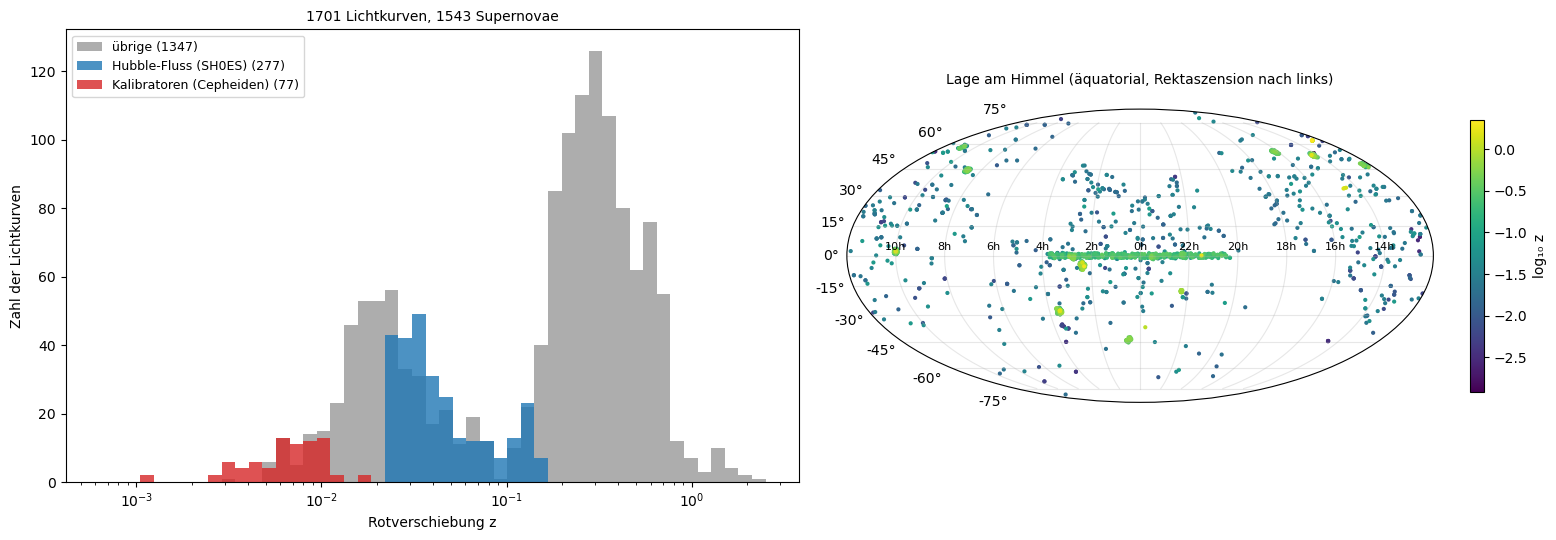

Lichtkurven pro Supernova: 1 bei 1416, 2 bei 98, 3 oder mehr bei 29
Median z: alle 0.164, z < 0.1: 44%, z > 1: 25 Lichtkurven
Kalibratoren: 1981B, 1990N, 1994ae, 1995al, 1997bp, 1997bq, 1998aq, 1998dh, 1999cp, 1999dq, 2001bg, 2001el ...


In [3]:
grp = np.where(CAL, "Kalibratoren (Cepheiden)", np.where(HF, "Hubble-Fluss (SH0ES)", "übrige"))
fig = plt.figure(figsize=(16, 5.5))
ax = fig.add_subplot(1, 2, 1)
bins = np.logspace(-3.2, 0.4, 50)
for g, col in [("übrige", "0.6"), ("Hubble-Fluss (SH0ES)", "C0"), ("Kalibratoren (Cepheiden)", "C3")]:
    ax.hist(SN.loc[grp == g, "zHD"], bins=bins, color=col, alpha=0.8, label=f"{g} ({(grp == g).sum()})")
ax.set_xscale("log")
ax.set_xlabel("Rotverschiebung z")
ax.set_ylabel("Zahl der Lichtkurven")
ax.set_title(f"{N} Lichtkurven, {SN['CID'].nunique()} Supernovae", fontsize=10)
ax.legend(fontsize=9)
ax = fig.add_subplot(1, 2, 2, projection="mollweide")
ra = np.radians(SN["RA"].values)
ra = np.where(ra > np.pi, ra - 2 * np.pi, ra)
sc = ax.scatter(-ra, np.radians(SN["DEC"]), c=np.log10(SN["zHD"]), s=4, cmap="viridis")
plt.colorbar(sc, ax=ax, shrink=0.6, label="log₁₀ z")
ax.grid(alpha=0.3)
ax.set_xticklabels([f"{int(((-x) % 360) / 15)}h" for x in range(-150, 151, 30)], fontsize=8)
ax.set_title("Lage am Himmel (äquatorial, Rektaszension nach links)", fontsize=10, pad=18)
plt.tight_layout()
plt.show()

dup = SN["CID"].value_counts()
print(f"Lichtkurven pro Supernova: 1 bei {np.sum(dup == 1)}, 2 bei {np.sum(dup == 2)}, 3 oder mehr bei {np.sum(dup >= 3)}")
print(f"Median z: alle {SN['zHD'].median():.3f}, z < 0.1: {np.mean(SN['zHD'] < 0.1):.0%}, z > 1: {np.sum(SN['zHD'] > 1)} Lichtkurven")
print("Kalibratoren:", ", ".join(sorted(SN.loc[CAL, "CID"].unique())[:12]), "...")

* Links die Verteilung der Rotverschiebungen auf logarithmischer Achse: rot die 77 Lichtkurven der Kalibratoren (z = 0.001 bis 0.017), blau die 277 im Hubble-Fluss von SH0ES (z = 0.023 bis 0.15), grau der Rest. Rechts die Lage am Himmel; das Band entlang des Äquators ist der Streifen 82 von SDSS, die Häufchen sind die tiefen Felder von SNLS, DES und Pan-STARRS.
* Zur Vorhersage: Im Median liegen die Lichtkurven bei z = 0.16, 44 % unter z = 0.1, aber das größte Maximum liegt bei z ≈ 0.3. Tiefe Durchmusterungen finden auf kleiner Fläche viele ferne Supernovae, weil das Volumen mit der Entfernung wächst; nahe Supernovae muss man über den ganzen Himmel suchen.
* 1416 Supernovae haben eine Lichtkurve, 98 zwei und 29 drei oder mehr: Dieselbe Explosion wurde von mehreren Durchmusterungen beobachtet. Diese Doppelungen kommen in Schritt 4 und 10 wieder.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-2"></a>

##### *2. Das Hubble-Diagramm*

Wie hängt die Helligkeit der Supernovae von ihrer Rotverschiebung ab, bevor man irgendetwas anpasst? Vorher vorhersagen: Wenn die Entfernung zehnmal größer ist, um wie viele Magnituden ist eine Standardkerze schwächer?

Links steht die standardisierte scheinbare Helligkeit `m_b_corr` gegen z, mit Linien für das Hubble-Gesetz d = cz/H₀ bei zwei Werten von H₀ und M = −19.25. Rechts die Abweichung von einem leeren Universum (ohne Materie und ohne kosmologische Konstante), damit man die Krümmung des Diagramms sieht. Dazu die Kurven für ein Universum nur aus Materie und für ΛCDM.

**Hintergrund & Fachbegriffe:**
- **Hubble-Diagramm:** Entfernungsmaß gegen Rotverschiebung; Hubble zeigte 1929 so, dass Galaxien sich umso schneller entfernen, je weiter sie weg sind.
- **Standardisierte Helligkeit:** m_b_corr ist die Helligkeit im Maximum, korrigiert für Breite der Lichtkurve (x1), Farbe (c), Masse der Wirtsgalaxie und Auswahleffekte; sie ist die Größe, die bis auf eine Konstante der Entfernungsmodul ist.
- **Leeres Universum:** ein Modell ohne Materie und Energie, das gleichmäßig expandiert; ein bequemer Bezug, gegen den sich Bremsung (unter der Linie) und Beschleunigung (über der Linie) ablesen lassen.

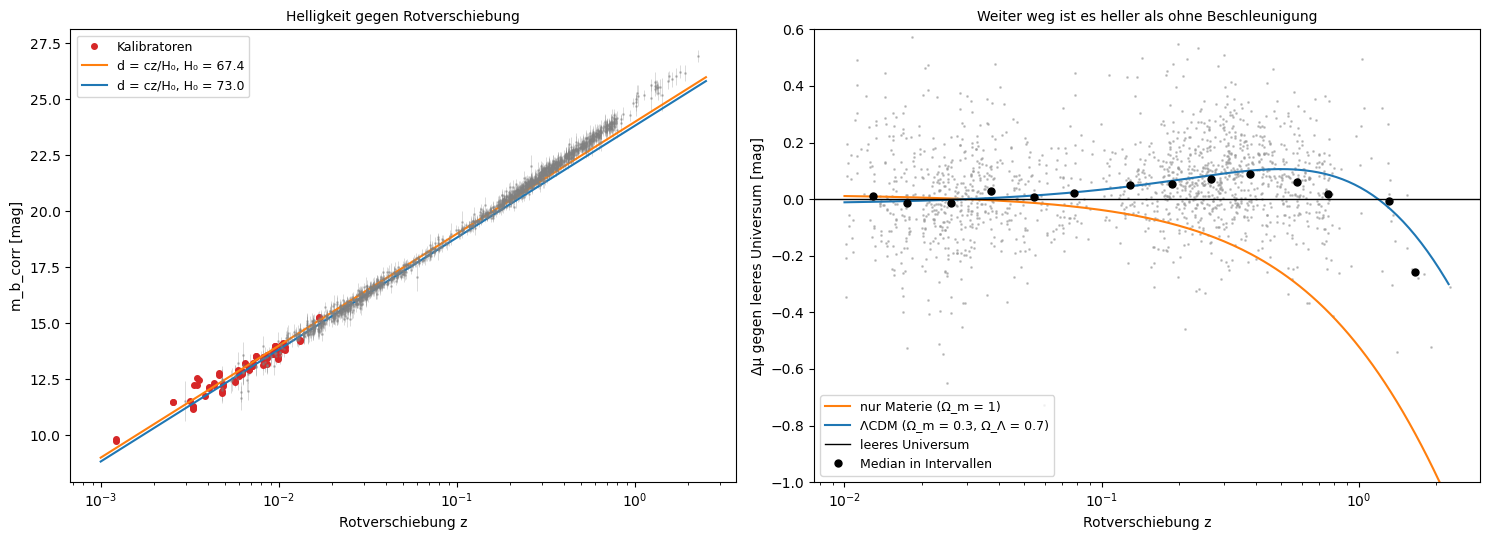

Streuung um eine Gerade im Hubble-Fluss (0.023 < z < 0.15): 0.148 mag; typischer Fehler pro Lichtkurve 0.217 mag
Abweichung vom leeren Universum bei 0.4 < z < 0.8 (Median, auf z ≈ 0.03 normiert): +0.072 mag


In [4]:
z, zhel, mb = SN["zHD"].values, SN["zHEL"].values, SN["m_b_corr"].values
err = SN["m_b_corr_err_DIAG"].values
M0 = -19.25
zz = np.logspace(-3, 0.4, 300)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
ax = axes[0]
ax.errorbar(z[~CAL], mb[~CAL], yerr=err[~CAL], fmt=".", ms=2, color="0.5", alpha=0.4, elinewidth=0.5)
ax.plot(z[CAL], mb[CAL], "o", color="C3", ms=4, label="Kalibratoren")
for H0, col in [(67.4, "C1"), (73.0, "C0")]:
    ax.plot(zz, M0 + 5 * np.log10(C_KMS * zz / H0) + 25, color=col, label=f"d = cz/H₀, H₀ = {H0}")
ax.set_xscale("log")
ax.set_xlabel("Rotverschiebung z")
ax.set_ylabel("m_b_corr [mag]")
ax.set_title("Helligkeit gegen Rotverschiebung", fontsize=10)
ax.legend(fontsize=9)
ax = axes[1]
empty = mu_model(z, 70, 0.0, 0.0, zhel)
sel = z > Z_MIN_COSMO
res = mb - empty
off = np.median(res[sel & (z < 0.1)])
zb = np.logspace(-2, 0.35, 15)
idx = np.digitize(z, zb)
ax.plot(z[sel], res[sel] - off, ".", ms=2, color="0.6", alpha=0.5)
ax.errorbar([np.median(z[idx == k]) for k in range(1, len(zb)) if (idx == k).sum() > 4],
            [np.median(res[idx == k] - off) for k in range(1, len(zb)) if (idx == k).sum() > 4],
            fmt="ko", ms=5, label="Median in Intervallen")
ze = np.logspace(-2, 0.35, 200)
base = mu_model(ze, 70, 0.0, 0.0)
for (Om, Ol), col, lab in [((1.0, 0.0), "C1", "nur Materie (Ω_m = 1)"), ((0.3, 0.7), "C0", "ΛCDM (Ω_m = 0.3, Ω_Λ = 0.7)")]:
    m = mu_model(ze, 70, Om, Ol)
    ax.plot(ze, m - base - np.interp(0.03, ze, m - base), color=col, label=lab)
ax.axhline(0, color="k", lw=1, label="leeres Universum")
ax.set_xscale("log")
ax.set_ylim(-1.0, 0.6)
ax.set_xlabel("Rotverschiebung z")
ax.set_ylabel("Δμ gegen leeres Universum [mag]")
ax.set_title("Weiter weg ist es heller als ohne Beschleunigung", fontsize=10)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

hi = (z > 0.4) & (z < 0.8)
print(f"Streuung um eine Gerade im Hubble-Fluss (0.023 < z < 0.15): {np.std(mb[HF] - (5 * np.log10(z[HF]))):.3f} mag; "
      f"typischer Fehler pro Lichtkurve {np.median(err):.3f} mag")
print(f"Abweichung vom leeren Universum bei 0.4 < z < 0.8 (Median, auf z ≈ 0.03 normiert): {np.median(res[hi] - off):+.3f} mag")

* Links die standardisierte Helligkeit gegen z: Die Punkte liegen auf einer Geraden mit Steigung 5 pro Dekade in z, wie es d ∝ z verlangt. Die Kalibratoren (rot) bei z < 0.02 streuen stärker, weil dort die Eigenbewegungen groß sind; ihre Entfernungen kommen aber nicht aus z, sondern aus Cepheiden. Die beiden Linien für H₀ = 67.4 und 73 liegen nur 5 log₁₀(73/67.4) = 0.17 mag auseinander, so klein ist der Unterschied, um den gestritten wird.
* Zur Vorhersage: Zehnmal weiter heißt hundertmal weniger Licht, also 5 mag schwächer.
* Rechts dasselbe gegen ein leeres Universum: Bei z = 0.4 bis 0.8 liegen die Supernovae im Median 0.07 mag darüber, also weiter weg und schwächer als ohne Beschleunigung; ein Universum nur aus Materie (orange) läge darunter. Jenseits von z ≈ 1 biegt die Kurve um: Damals dominierte noch die Materie, und die Expansion bremste.

[↑ Zurück zur Landkarte](#landkarte)

#### **Reduktion**

<a id="exp-3"></a>

##### *3. Rotverschiebungen und Eigenbewegungen*

Welche Rotverschiebung ist die richtige, und warum spielt das bei nahen Supernovae eine so große Rolle? Vorher vorhersagen: Wie groß ist der Fehler im Entfernungsmodul, wenn eine Galaxie in 50 Mpc (cz ≈ 3500 km/s) eine Eigenbewegung von 300 km/s hat?

Pantheon+ gibt drei Rotverschiebungen: heliozentrisch (`zHEL`, wie gemessen), im Ruhesystem der Hintergrundstrahlung (`zCMB`, ohne die Bewegung der Sonne) und `zHD`, zusätzlich korrigiert für die Eigenbewegung der Wirtsgalaxie aus einer Karte des lokalen Dichtefelds. Der Code zeigt die Unterschiede und was sie im Entfernungsmodul ausmachen, Δμ = 5 log₁₀(z₁/z₂).

**Hintergrund & Fachbegriffe:**
- **Eigenbewegung:** die Geschwindigkeit einer Galaxie relativ zur reinen Expansion, durch die Anziehung benachbarter Massen; typisch 200 bis 400 km/s.
- **Dipol der Hintergrundstrahlung:** Die Sonne bewegt sich mit 370 km/s gegenüber der Hintergrundstrahlung; die Korrektur von zHEL auf zCMB hängt deshalb von der Himmelsrichtung ab.
- **Rekonstruiertes Geschwindigkeitsfeld:** aus der Verteilung der Galaxien (2M++) berechnete Eigenbewegungen, mit einer Unsicherheit von etwa 250 km/s (`VPECERR`).

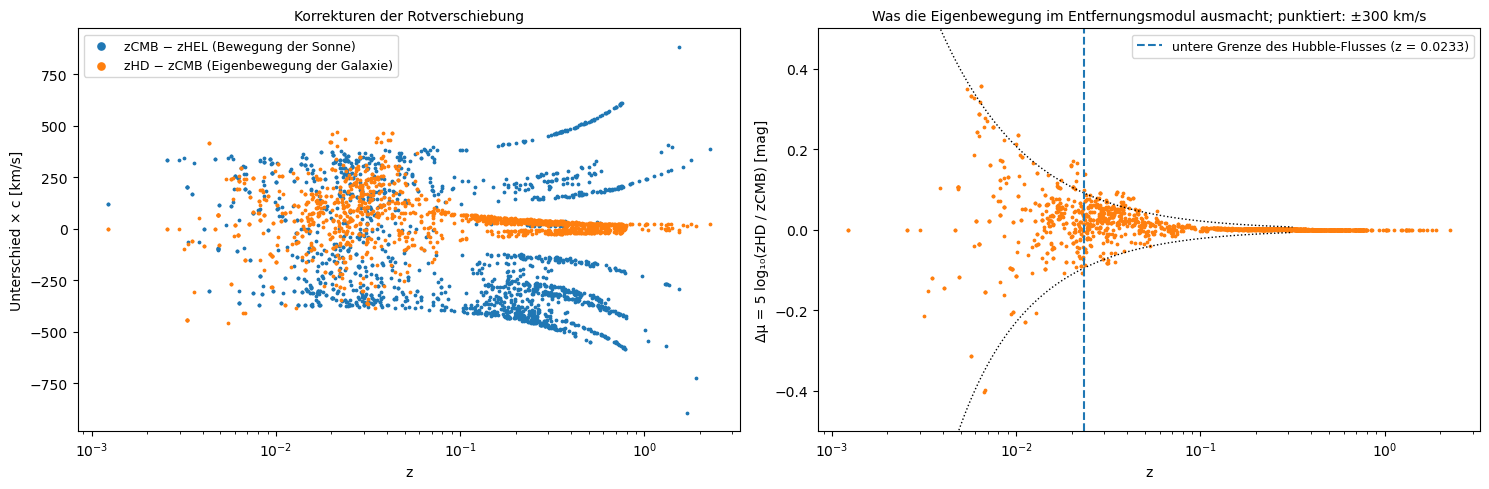

z 0.0000 bis 0.01  :  111 Lichtkurven, |zHD − zCMB|·c Median   135 km/s, |Δμ| Median 0.123 mag
z 0.0100 bis 0.0233:  225 Lichtkurven, |zHD − zCMB|·c Median   114 km/s, |Δμ| Median 0.048 mag
z 0.0233 bis 0.15  :  490 Lichtkurven, |zHD − zCMB|·c Median    90 km/s, |Δμ| Median 0.017 mag
z 0.1500 bis 3     :  875 Lichtkurven, |zHD − zCMB|·c Median    27 km/s, |Δμ| Median 0.001 mag
VPECERR: Median 250 km/s


In [5]:
dz_cmb = SN["zCMB"] - SN["zHEL"]
dz_pec = SN["zHD"] - SN["zCMB"]
dmu = 5 * np.log10(SN["zHD"] / SN["zCMB"])
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ax = axes[0]
ax.scatter(SN["zHD"], C_KMS * dz_cmb, s=3, label="zCMB − zHEL (Bewegung der Sonne)")
ax.scatter(SN["zHD"], C_KMS * dz_pec, s=3, label="zHD − zCMB (Eigenbewegung der Galaxie)")
ax.set_xscale("log")
ax.set_xlabel("z")
ax.set_ylabel("Unterschied × c [km/s]")
ax.set_title("Korrekturen der Rotverschiebung", fontsize=10)
ax.legend(fontsize=9, markerscale=3)
ax = axes[1]
ax.scatter(SN["zHD"], dmu, s=3, c="C1")
zz = np.logspace(np.log10(0.0025), -0.5, 100)                   # erst ab cz > 300 km/s ist 1 − 300/cz positiv
for v in (300, -300):
    ax.plot(zz, 5 * np.log10(1 + v / (C_KMS * zz)), "k:", lw=1)
ax.axvline(Z_HF[0], color="C0", ls="--", label=f"untere Grenze des Hubble-Flusses (z = {Z_HF[0]})")
ax.set_xscale("log")
ax.set_ylim(-0.5, 0.5)
ax.set_xlabel("z")
ax.set_ylabel("Δμ = 5 log₁₀(zHD / zCMB) [mag]")
ax.set_title("Was die Eigenbewegung im Entfernungsmodul ausmacht; punktiert: ±300 km/s", fontsize=10)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

for lo, hi in [(0, 0.01), (0.01, 0.0233), (0.0233, 0.15), (0.15, 3)]:
    m = (SN["zHD"] >= lo) & (SN["zHD"] < hi)
    print(f"z {lo:6.4f} bis {hi:<6}: {m.sum():4d} Lichtkurven, |zHD − zCMB|·c Median {np.median(np.abs(C_KMS * dz_pec[m])):5.0f} km/s, "
          f"|Δμ| Median {np.median(np.abs(dmu[m])):.3f} mag")
print(f"VPECERR: Median {SN['VPECERR'].median():.0f} km/s")

* Links die beiden Korrekturen in km/s. Die Bewegung der Sonne gegen die Hintergrundstrahlung (blau) liegt je nach Himmelsrichtung zwischen −370 und +370 km/s, bei großem z mit (1 + z) gestreckt; die Bänder sind einzelne tiefe Felder mit fester Richtung, deren Korrektur mit (1 + z) wächst. Die Eigenbewegungen der Wirtsgalaxien (orange) sind nur bis z ≈ 0.1 berechnet, danach fast null.
* Rechts, was die Eigenbewegung im Entfernungsmodul ausmacht, mit den Kurven für ±300 km/s: unter z = 0.01 im Median 0.12 mag, zwischen 0.01 und 0.023 0.05 mag, im Hubble-Fluss 0.017 mag, darüber 0.001 mag. Die angenommene Unsicherheit der Eigenbewegungen ist 250 km/s.
* Zur Vorhersage: 300 km/s bei cz = 3500 km/s sind 8.6 %, also 5 log₁₀(1.086) = 0.18 mag im Entfernungsmodul, mehr als die Streuung einer Supernova. Deshalb beginnt der Hubble-Fluss erst bei z = 0.023.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-4"></a>

##### *4. Die Kovarianzmatrix*

Wie stark hängen die Fehler verschiedener Supernovae zusammen, und welcher Teil der Unsicherheit ist für alle gleich? Vorher vorhersagen: Wenn alle Supernovae einer Durchmusterung denselben Kalibrierfehler des Filters haben, mittelt sich dieser Fehler mit mehr Supernovae heraus?

Der Code zerlegt die Kovarianzmatrix in Diagonale (Fehler jeder Lichtkurve für sich) und Nebendiagonale (gemeinsame Fehler), zeigt die Korrelationsmatrix nach z sortiert und prüft, wie stark zwei Lichtkurven derselben Supernova korrelieren. Rechts die Eigenwerte: Wenige große Eigenwerte bedeuten wenige gemeinsame Fehlermuster, die alle Supernovae zugleich verschieben.

**Hintergrund & Fachbegriffe:**
- **Kovarianz:** C_ij = ⟨δ_i δ_j⟩; auf der Diagonale die Varianzen, daneben, wie sehr die Fehler von i und j gemeinsam schwanken. Korrelation ρ_ij = C_ij/√(C_ii C_jj).
- **Systematischer Fehler:** ein Fehler, der viele Messungen gleich verschiebt (falsche Nullpunkte der Filter, ein falsches Staubgesetz); er mittelt sich nicht heraus.
- **Eigenwertzerlegung:** C = Σ λ_k v_k v_kᵀ; jeder Eigenvektor ist ein Muster gemeinsamer Fehler, sein Eigenwert dessen Varianz.

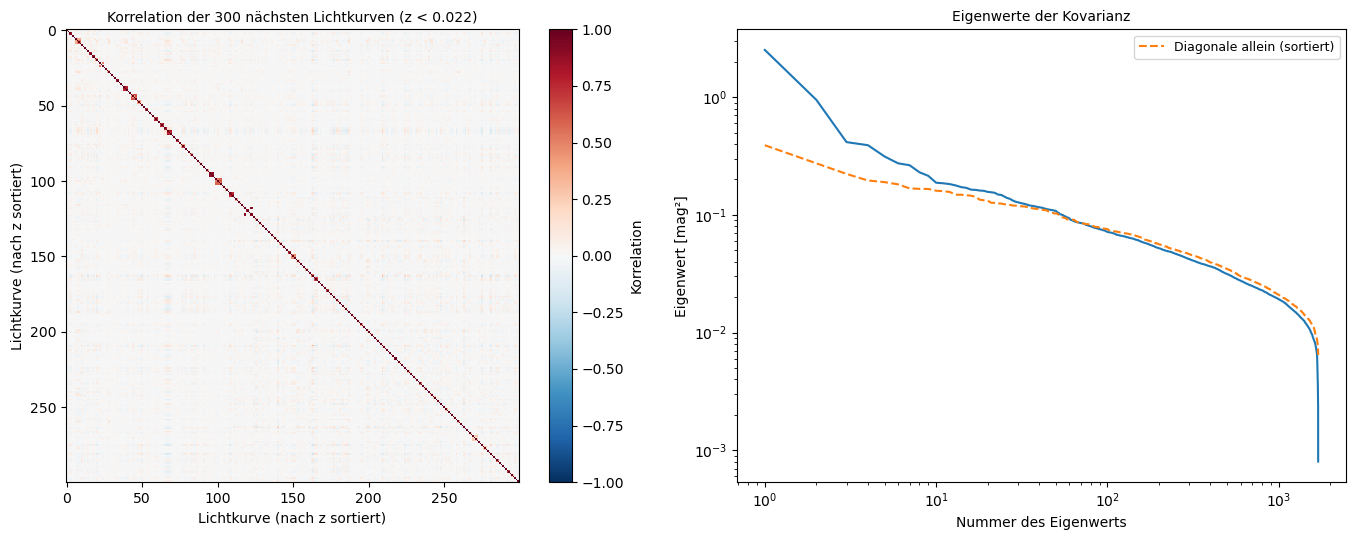

Diagonale: Fehler pro Lichtkurve Median 0.156 mag; Nebendiagonale: Median der Korrelation -0.000, Anteil > 0.1: 2.0%
Zwei Lichtkurven derselben Supernova (191 Paare): Korrelation Median 0.41
Größter Eigenwert 2.5237 mag² (σ = 1.589), die 10 größten zusammen 10.5% der Spur
Fehler des Mittelwerts aller 1701 Lichtkurven: nur Diagonale 0.0044 mag, volle Kovarianz 0.0049 mag


In [6]:
order = np.argsort(SN["zHD"].values)
sd = np.sqrt(np.diag(COV))
CORR = COV / np.outer(sd, sd)
lam = np.linalg.eigvalsh(COV)[::-1]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
ax = axes[0]
near300 = order[:300]
im = ax.imshow(CORR[np.ix_(near300, near300)], cmap="RdBu_r", vmin=-1, vmax=1, interpolation="nearest")
plt.colorbar(im, ax=ax, label="Korrelation")
ax.set_xlabel("Lichtkurve (nach z sortiert)")
ax.set_ylabel("Lichtkurve (nach z sortiert)")
ax.set_title(f"Korrelation der 300 nächsten Lichtkurven (z < {SN['zHD'].values[near300].max():.3f})", fontsize=10)
ax = axes[1]
ax.semilogy(np.arange(1, N + 1), lam, "C0-")
ax.semilogy(np.arange(1, N + 1), np.sort(np.diag(COV))[::-1], "C1--", label="Diagonale allein (sortiert)")
ax.set_xscale("log")
ax.set_xlabel("Nummer des Eigenwerts")
ax.set_ylabel("Eigenwert [mag²]")
ax.set_title("Eigenwerte der Kovarianz", fontsize=10)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

off_diag = COV - np.diag(np.diag(COV))
dups = [g.index.values for _, g in SN.groupby("CID") if len(g) > 1]
rho_dup = [CORR[i, j] for g in dups for a, i in enumerate(g) for j in g[a + 1:]]
iu = np.triu_indices(N, 1)
print(f"Diagonale: Fehler pro Lichtkurve Median {np.median(sd):.3f} mag; Nebendiagonale: Median der Korrelation {np.median(CORR[iu]):.3f}, "
      f"Anteil > 0.1: {np.mean(CORR[iu] > 0.1):.1%}")
print(f"Zwei Lichtkurven derselben Supernova ({len(rho_dup)} Paare): Korrelation Median {np.median(rho_dup):.2f}")
print(f"Größter Eigenwert {lam[0]:.4f} mag² (σ = {np.sqrt(lam[0]):.3f}), die 10 größten zusammen {lam[:10].sum() / lam.sum():.1%} der Spur")
w = np.ones(N) / N
print(f"Fehler des Mittelwerts aller {N} Lichtkurven: nur Diagonale {np.sqrt(w @ np.diag(np.diag(COV)) @ w):.4f} mag, "
      f"volle Kovarianz {np.sqrt(w @ COV @ w):.4f} mag")

* Links die Korrelationsmatrix der 300 nächsten Lichtkurven: fast überall weiß (unkorreliert), mit einzelnen roten Punkten neben der Diagonale. Im ganzen Katalog sind nur 2.0 % der Paare stärker als 0.1 korreliert; aber zwei Lichtkurven derselben Supernova korrelieren im Median zu 0.41.
* Rechts die Eigenwerte gegen die Varianzen der Diagonale: Die größten Eigenwerte liegen weit über den größten Diagonalelementen. Der größte (2.5 mag²) gehört vermutlich zu den nächsten Supernovae, deren Fehler durch die Eigenbewegung über 1 mag beträgt; die 10 größten tragen 10.5 % der gesamten Varianz.
* Zur Vorhersage: Nein. Der Mittelwert aller 1701 Lichtkurven ist mit der Diagonale allein auf 0.0044 mag genau, mit voller Kovarianz auf 0.0049 mag: Ein gemeinsamer Fehler mittelt sich nicht heraus, und genau er bestimmt am Ende die Genauigkeit.

[↑ Zurück zur Landkarte](#landkarte)

#### **Eigene Messung**

<a id="exp-5"></a>

##### *5. Die Kalibratoren: wie hell ist eine Supernova?*

Welche absolute Helligkeit M_B hat eine standardisierte Supernova vom Typ Ia, wenn man ihre Entfernung aus Cepheiden kennt? Vorher vorhersagen: Wie genau lässt sich M_B aus etwa 40 Supernovae bestimmen, wenn jede 0.15 mag streut?

Für jede Kalibrator-Lichtkurve ist M_B = m_b_corr − μ_Cepheiden. Der gewichtete Mittelwert mit der vollen Kovarianz der 77 Lichtkurven (die mehrfach beobachteten Supernovae sind stark korreliert) gibt M_B. Links jede Supernova mit Fehler, rechts der Vergleich der Kalibratoren mit dem Hubble-Fluss: Beide sollen dieselbe Standardisierung haben, sonst ist die Entfernungsleiter verbogen.

**Hintergrund & Fachbegriffe:**
- **Absolute Helligkeit:** die scheinbare Helligkeit in 10 pc Entfernung; M = m − μ.
- **Entfernungsleiter:** Parallaxen eichen Cepheiden in der Milchstraße, Cepheiden die Entfernung von Galaxien mit Supernovae, Supernovae die Entfernungen im Hubble-Fluss (Theorie, Abschnitt 4).
- **Gewichteter Mittelwert mit Kovarianz:** M = (1ᵀC⁻¹r)/(1ᵀC⁻¹1), Fehler 1/√(1ᵀC⁻¹1); bei korrelierten Messungen zählt eine doppelt beobachtete Supernova nicht doppelt.

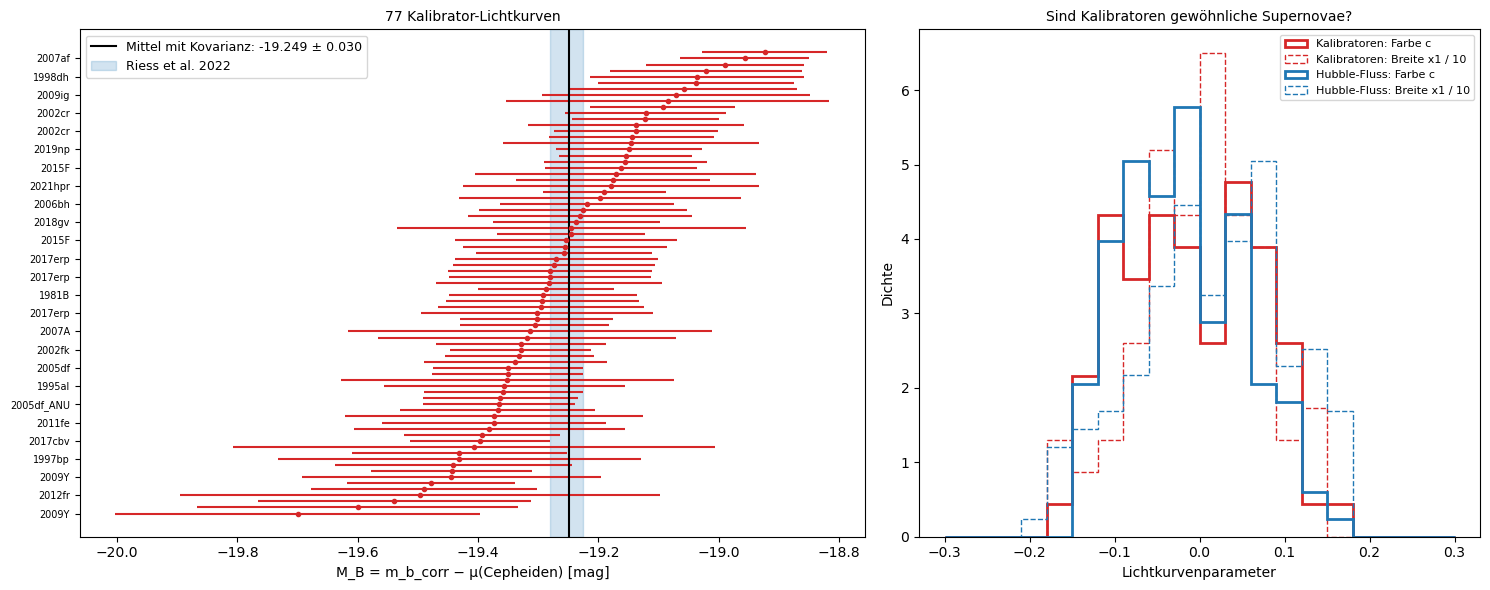

M_B = -19.2489 ± 0.0301 (volle Kovarianz), diagonal gewichtet -19.2447; Riess et al. 2022: -19.253 ± 0.027
χ² = 57.1 bei 76 Freiheitsgraden; Streuung der Einzelwerte 0.146 mag
c            : Kalibratoren Median -0.026, Hubble-Fluss -0.026; KS-Test p = 0.39
x1           : Kalibratoren Median +0.062, Hubble-Fluss +0.196; KS-Test p = 0.06
HOST_LOGMASS : Kalibratoren Median +10.353, Hubble-Fluss +9.989; KS-Test p = 0.00


In [7]:
ic = np.where(CAL)[0]
r_cal = SN["m_b_corr"].values[ic] - SN["CEPH_DIST"].values[ic]
(M_CAL,), covM, chi2_cal = gls(r_cal, np.ones((len(ic), 1)), subcov(ic))
M_CAL_ERR = np.sqrt(covM[0, 0])
M_diag = np.average(r_cal, weights=1 / np.diag(subcov(ic)))
names = SN["CID"].values[ic]

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.4, 1]})
ax = axes[0]
o = np.argsort(r_cal)
ax.errorbar(r_cal[o], np.arange(len(ic)), xerr=np.sqrt(np.diag(subcov(ic)))[o], fmt="o", ms=3, color="C3")
ax.axvline(M_CAL, color="k", label=f"Mittel mit Kovarianz: {M_CAL:.3f} ± {M_CAL_ERR:.3f}")
ax.axvspan(*LIT["M_SH0ES"][0] + np.array([-1, 1]) * LIT["M_SH0ES"][1], color="C0", alpha=0.2, label="Riess et al. 2022")
ax.set_yticks(np.arange(len(ic))[::3])
ax.set_yticklabels(names[o][::3], fontsize=7)
ax.set_xlabel("M_B = m_b_corr − μ(Cepheiden) [mag]")
ax.set_title(f"{len(ic)} Kalibrator-Lichtkurven", fontsize=10)
ax.legend(fontsize=9)
ax = axes[1]
for m, col, lab in [(CAL, "C3", "Kalibratoren"), (HF, "C0", "Hubble-Fluss")]:
    ax.hist(SN.loc[m, "c"], bins=np.arange(-0.3, 0.31, 0.03), histtype="step", lw=2, color=col, density=True, label=f"{lab}: Farbe c")
    ax.hist(SN.loc[m, "x1"] / 10, bins=np.arange(-0.3, 0.31, 0.03), histtype="step", lw=1, ls="--", color=col, density=True,
            label=f"{lab}: Breite x1 / 10")
ax.set_xlabel("Lichtkurvenparameter")
ax.set_ylabel("Dichte")
ax.set_title("Sind Kalibratoren gewöhnliche Supernovae?", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"M_B = {M_CAL:.4f} ± {M_CAL_ERR:.4f} (volle Kovarianz), diagonal gewichtet {M_diag:.4f}; Riess et al. 2022: "
      f"{LIT['M_SH0ES'][0]} ± {LIT['M_SH0ES'][1]}")
print(f"χ² = {chi2_cal:.1f} bei {len(ic) - 1} Freiheitsgraden; Streuung der Einzelwerte {np.std(r_cal):.3f} mag")
for p in ("c", "x1", "HOST_LOGMASS"):
    a, b = SN.loc[CAL, p], SN.loc[HF, p]
    a, b = a[a > -9], b[b > -9]
    print(f"{p:13s}: Kalibratoren Median {a.median():+.3f}, Hubble-Fluss {b.median():+.3f}; KS-Test p = {stats.ks_2samp(a, b).pvalue:.2f}")

* Links die 77 Kalibrator-Lichtkurven, jede als M_B = m_b_corr − μ_Cepheiden mit Fehler. Sie streuen um 0.146 mag; der Mittelwert mit voller Kovarianz ist M_B = −19.249 ± 0.030 und liegt im Band von Riess et al. (2022), −19.253 ± 0.027. χ² = 57 bei 76 Freiheitsgraden zeigt, dass die Fehler eher zu groß als zu klein angesetzt sind.
* Zur Vorhersage: 0.15 mag / √43 = 0.023 mag; tatsächlich sind es 0.030, weil die Fehler der Cepheiden-Entfernungen und die Korrelationen dazukommen.
* Rechts Farbe c und Breite x1 der Kalibratoren und des Hubble-Flusses: Die Farben sind gleich verteilt (KS-Test p = 0.39), die Breiten fast (p = 0.06). Die Wirtsgalaxien der Kalibratoren sind aber massereicher (log M = 10.35 gegen 9.99, p < 0.01); deshalb ist die Korrektur nach der Masse der Wirtsgalaxie für H₀ wichtig.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-6"></a>

##### *6. Der Hubble-Fluss*

Wie hell erscheint eine Standardkerze bei gegebener Rotverschiebung, und was folgt daraus für H₀, wenn man M_B schon kennt? Vorher vorhersagen: Wenn M_B um 0.1 mag heller wäre, um wie viel Prozent ändert sich H₀?

Im Hubble-Fluss gilt bei kleinem z, mit einer Taylor-Reihe in z (Theorie, Abschnitt 2):
log₁₀(cz [1 + ½(1 − q₀) z − ⅙(1 − q₀ − 3q₀² + j₀) z²]) − 0.2 m = a_B. Der Achsenabschnitt a_B hängt nicht von H₀ ab; erst mit M_B folgt log₁₀ H₀ = 0.2 M_B + a_B + 5 (Riess et al. 2016). Der Code bestimmt a_B für die 277 Lichtkurven mit voller Kovarianz (q₀ = −0.55, j₀ = 1) und daraus H₀.

**Hintergrund & Fachbegriffe:**
- **Achsenabschnitt a_B:** der Abstand der Supernovae von einer Hubble-Geraden in log-Einheiten; er misst die scheinbare Helligkeit einer Standardkerze bei bekannter Rotverschiebung.
- **Bremsparameter q₀:** q₀ = −ä a/ȧ² heute; negativ heißt beschleunigt. In ΛCDM ist q₀ = Ω_m/2 − Ω_Λ ≈ −0.55.
- **Ruck j₀:** die dritte Ableitung des Skalenfaktors; in flachem ΛCDM genau 1.

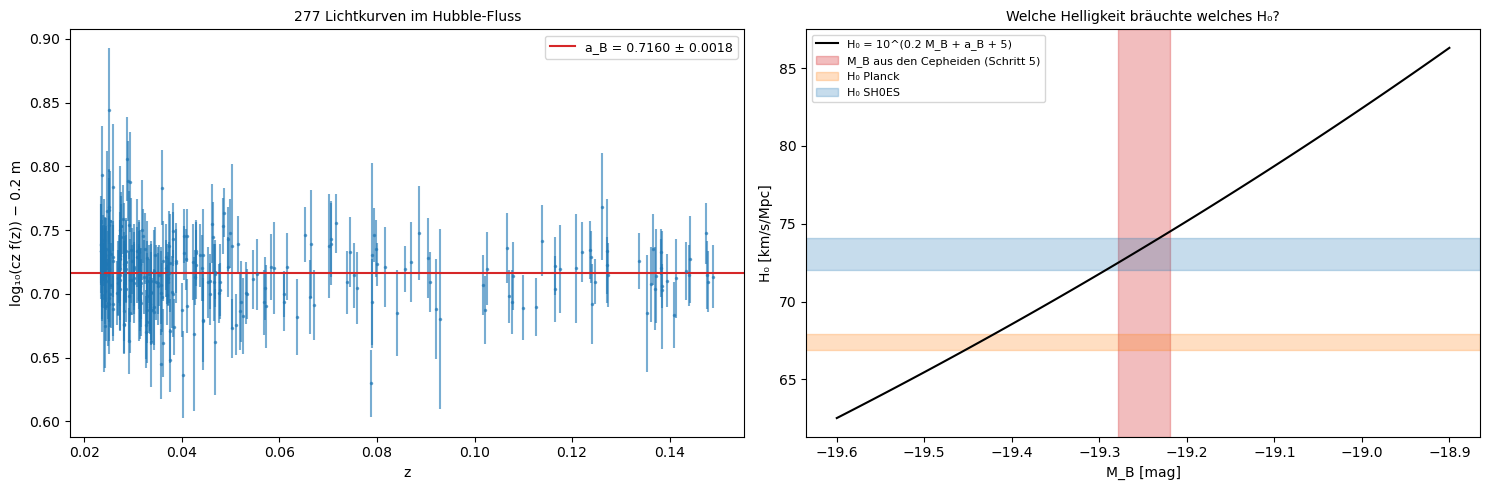

a_B = 0.71599 ± 0.00181 (χ² = 230.7 bei 276 Freiheitsgraden)
H₀ = 10^(0.2 · -19.249 + 0.7160 + 5) = 73.49 ± 1.06 km/s/Mpc
Für H₀ = 67.4 müsste M_B = -19.437 sein, -0.188 mag (-6.2 σ) neben dem Wert der Cepheiden


In [8]:
Q0, J0 = -0.55, 1.0
ih = np.where(HF)[0]
zh = SN["zHD"].values[ih]
mh = SN["m_b_corr"].values[ih]
f_z = 1 + 0.5 * (1 - Q0) * zh - (1 - Q0 - 3 * Q0**2 + J0) * zh**2 / 6
y_a = np.log10(C_KMS * zh * f_z) - 0.2 * mh                          # jede Lichtkurve gibt ein a_B
cov_a = 0.04 * subcov(ih)                                            # 0.2² × Kovarianz der Helligkeiten
(A_B,), covA, chi2_a = gls(y_a, np.ones((len(ih), 1)), cov_a)
A_B_ERR = np.sqrt(covA[0, 0])
H0_SIMPLE = 10 ** (0.2 * M_CAL + A_B + 5)
H0_SIMPLE_ERR = H0_SIMPLE * np.log(10) * np.hypot(0.2 * M_CAL_ERR, A_B_ERR)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ax = axes[0]
ax.errorbar(zh, y_a, yerr=0.2 * np.sqrt(np.diag(subcov(ih))), fmt=".", ms=3, alpha=0.6)
ax.axhline(A_B, color="C3", label=f"a_B = {A_B:.4f} ± {A_B_ERR:.4f}")
ax.set_xlabel("z")
ax.set_ylabel("log₁₀(cz f(z)) − 0.2 m")
ax.set_title(f"{len(ih)} Lichtkurven im Hubble-Fluss", fontsize=10)
ax.legend(fontsize=9)
ax = axes[1]
Mg = np.linspace(-19.6, -18.9, 100)
ax.plot(Mg, 10 ** (0.2 * Mg + A_B + 5), "k-", label="H₀ = 10^(0.2 M_B + a_B + 5)")
ax.axvspan(M_CAL - M_CAL_ERR, M_CAL + M_CAL_ERR, color="C3", alpha=0.3, label="M_B aus den Cepheiden (Schritt 5)")
for key, col in [("H0_Planck", "C1"), ("H0_SH0ES", "C0")]:
    ax.axhspan(LIT[key][0] - LIT[key][1], LIT[key][0] + LIT[key][1], color=col, alpha=0.25, label=key.replace("H0_", "H₀ "))
ax.set_xlabel("M_B [mag]")
ax.set_ylabel("H₀ [km/s/Mpc]")
ax.set_title("Welche Helligkeit bräuchte welches H₀?", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

M_for_planck = 5 * (np.log10(LIT["H0_Planck"][0]) - A_B - 5)
print(f"a_B = {A_B:.5f} ± {A_B_ERR:.5f} (χ² = {chi2_a:.1f} bei {len(ih) - 1} Freiheitsgraden)")
print(f"H₀ = 10^(0.2 · {M_CAL:.3f} + {A_B:.4f} + 5) = {H0_SIMPLE:.2f} ± {H0_SIMPLE_ERR:.2f} km/s/Mpc")
print(f"Für H₀ = {LIT['H0_Planck'][0]} müsste M_B = {M_for_planck:.3f} sein, {M_for_planck - M_CAL:+.3f} mag "
      f"({(M_for_planck - M_CAL) / M_CAL_ERR:.1f} σ) neben dem Wert der Cepheiden")

* Links jede Lichtkurve im Hubble-Fluss als eigene Schätzung von a_B: Sie liegen ohne Trend mit z um a_B = 0.7160 ± 0.0018; χ² = 231 bei 276 Freiheitsgraden.
* Rechts die Beziehung H₀ = 10^(0.2 M_B + a_B + 5): Mit M_B aus den Cepheiden folgt H₀ = 73.49 ± 1.06 km/s/Mpc. Für H₀ = 67.4 müssten Supernovae 0.19 mag heller sein (M_B = −19.437), 6.2σ neben dem Wert der Cepheiden.
* Zur Vorhersage: 0.1 mag in M_B sind 0.2 · ln 10 · 0.1 = 4.6 % in H₀. Weil a_B fast beliebig genau ist (0.0018 entspricht 0.4 %), hängt der Fehler von H₀ fast ganz an M_B, also an den Cepheiden.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-7"></a>

##### *7. H₀ im gemeinsamen Fit*

Wie groß ist H₀, wenn Kalibratoren und Hubble-Fluss zusammen mit allen Korrelationen angepasst werden? Vorher vorhersagen: Liegt das Ergebnis näher an 67 oder an 73 km/s/Mpc, und wie groß ist der Fehler ungefähr, wenn M_B auf 0.03 mag bekannt ist?

Der Code passt zwei Größen gleichzeitig an, M_B und H₀, mit der vollen Kovarianz aller 354 Lichtkurven aus Kalibratoren und Hubble-Fluss: Für Kalibratoren ist das Modell m = M_B + μ_Cepheiden, für den Hubble-Fluss m = M_B + μ_ΛCDM(z; H₀, Ω_m = 0.334). Das ist die Rechnung von Brout et al. (2022, Abschnitt 4). Links die Ellipse der beiden Größen, rechts die Residuen.

**Hintergrund & Fachbegriffe:**
- **Gemeinsamer Fit:** Kalibratoren legen M_B fest, der Hubble-Fluss die Kombination 5 log₁₀ H₀ − M_B; erst zusammen ist H₀ bestimmt. Die Kovarianz verbindet beide Teile, weil systematische Fehler (etwa die Kalibrierung eines Filters) Kalibratoren und Hubble-Fluss gemeinsam treffen.
- **Fehlerellipse:** Die Kurve Δχ² = 2.30 umschließt 68 % der Wahrscheinlichkeit für zwei Größen zusammen.

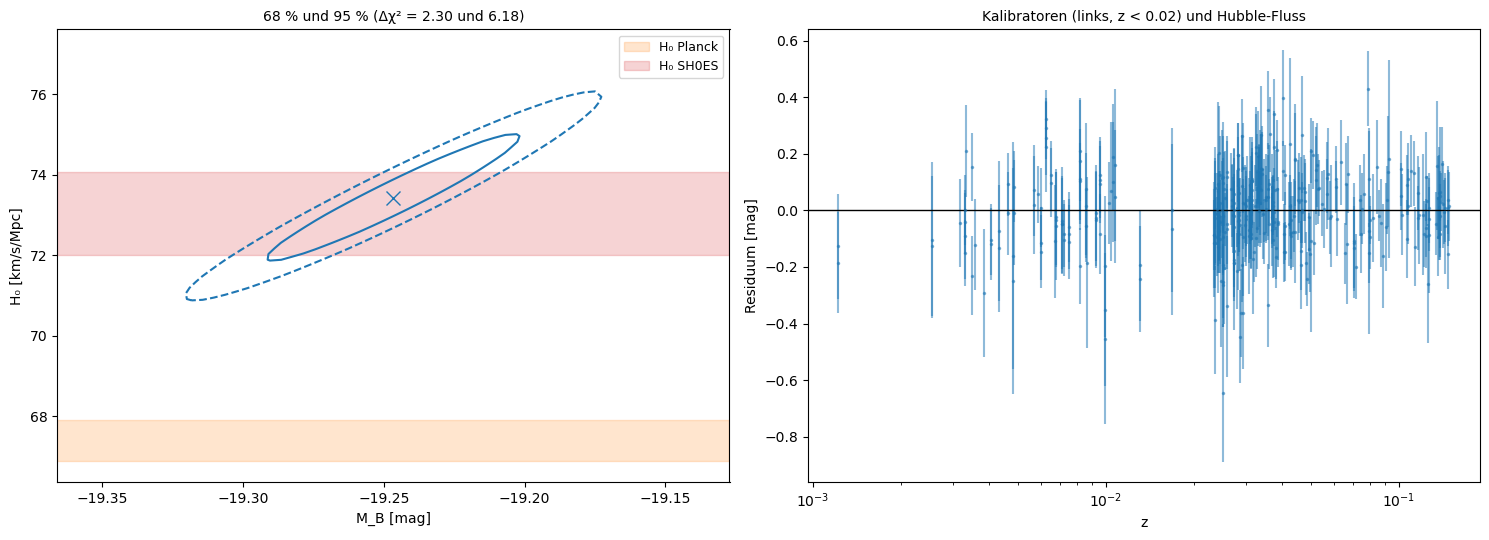

M_B = -19.2467 ± 0.0299, H₀ = 73.43 ± 1.05 km/s/Mpc, Korrelation +0.96; χ² = 299.8 bei 352 Freiheitsgraden
Schritt 6 (Achsenabschnitt): 73.49 ± 1.06; δH₀/H₀ = 0.46 · δM_B: 0.03 mag in M_B sind 1.4% in H₀


In [9]:
isel = np.where(CAL | HF)[0]
CJ = np.linalg.inv(subcov(isel))
zj, zhj = SN["zHD"].values[isel], SN["zHEL"].values[isel]
mj, ceph, is_cal = SN["m_b_corr"].values[isel], SN["CEPH_DIST"].values[isel], CAL[isel]


def chi2_joint(p, Om=OM_FIX, Ci=CJ):
    M, H0 = p
    model = np.where(is_cal, ceph, mu_model(zj, H0, Om, zhel=zhj))
    r = mj - M - model
    return r @ Ci @ r


fit = optimize.minimize(chi2_joint, [-19.25, 73.0], method="Nelder-Mead", options=dict(xatol=1e-7, fatol=1e-7))
M_J, H0_J = fit.x
COV_J = np.linalg.inv(hessian(chi2_joint, fit.x) / 2)
H0_J_ERR, M_J_ERR = np.sqrt(COV_J[1, 1]), np.sqrt(COV_J[0, 0])
rho = COV_J[0, 1] / (H0_J_ERR * M_J_ERR)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
ax = axes[0]
Mg, Hg = np.linspace(M_J - 4 * M_J_ERR, M_J + 4 * M_J_ERR, 61), np.linspace(H0_J - 4 * H0_J_ERR, H0_J + 4 * H0_J_ERR, 61)
D = np.array([[chi2_joint([a, b]) for a in Mg] for b in Hg]) - fit.fun
ax.contour(Mg, Hg, D, levels=[2.30, 6.18], colors=["C0", "C0"], linestyles=["-", "--"])
ax.plot(M_J, H0_J, "C0x", ms=10)
for key, col in [("H0_Planck", "C1"), ("H0_SH0ES", "C3")]:
    ax.axhspan(LIT[key][0] - LIT[key][1], LIT[key][0] + LIT[key][1], color=col, alpha=0.2, label=key.replace("H0_", "H₀ "))
ax.set_xlabel("M_B [mag]")
ax.set_ylabel("H₀ [km/s/Mpc]")
ax.set_title("68 % und 95 % (Δχ² = 2.30 und 6.18)", fontsize=10)
ax.legend(fontsize=9)
ax = axes[1]
model = np.where(is_cal, ceph, mu_model(zj, H0_J, OM_FIX, zhel=zhj))
ax.errorbar(zj, mj - M_J - model, yerr=np.sqrt(np.diag(subcov(isel))), fmt=".", ms=3, alpha=0.5)
ax.axhline(0, color="k", lw=1)
ax.set_xscale("log")
ax.set_xlabel("z")
ax.set_ylabel("Residuum [mag]")
ax.set_title("Kalibratoren (links, z < 0.02) und Hubble-Fluss", fontsize=10)
plt.tight_layout()
plt.show()

print(f"M_B = {M_J:.4f} ± {M_J_ERR:.4f}, H₀ = {H0_J:.2f} ± {H0_J_ERR:.2f} km/s/Mpc, Korrelation {rho:+.2f}; "
      f"χ² = {fit.fun:.1f} bei {len(isel) - 2} Freiheitsgraden")
print(f"Schritt 6 (Achsenabschnitt): {H0_SIMPLE:.2f} ± {H0_SIMPLE_ERR:.2f}; δH₀/H₀ = 0.46 · δM_B: "
      f"0.03 mag in M_B sind {0.2 * np.log(10) * 0.03:.1%} in H₀")

* Links die Fehlerellipse von M_B und H₀ aus dem gemeinsamen Fit: Sie ist lang und schmal, die Korrelation ist +0.96, weil H₀ im Hubble-Fluss nur zusammen mit M_B bestimmt ist. Ihr Schnitt mit dem Band von SH0ES ist groß, das Band von Planck liegt weit unter der 95-%-Ellipse.
* Rechts die Residuen aller 354 Lichtkurven ohne erkennbaren Gang mit z; χ² = 300 bei 352 Freiheitsgraden.
* Zur Vorhersage: H₀ = 73.43 ± 1.05 km/s/Mpc, also bei 73; der Fehler von 1.4 % entspricht 0.03 mag in M_B. Der gemeinsame Fit stimmt mit der Rechnung über den Achsenabschnitt (73.49) überein und mit Brout et al. (73.5 ± 1.1).

[↑ Zurück zur Landkarte](#landkarte)

#### **Modell und Fit**

<a id="exp-8"></a>

##### *8. Ω_m aus dem ganzen Diagramm*

Wie viel Materie braucht ein flaches Universum, damit es zu den Supernovae bis z = 2 passt? Vorher vorhersagen: Wenn die fernen Supernovae heller sind als in einem Universum nur aus Materie, ist Ω_m dann größer oder kleiner als 1?

Für alle Lichtkurven mit z > 0.01 außer den Kalibratoren passt der Code ein flaches ΛCDM an. H₀ und M_B sind dabei vollständig entartet (beide verschieben alle Helligkeiten gleich); χ² wird deshalb über eine additive Konstante analytisch minimiert, übrig bleibt allein Ω_m. Links χ²(Ω_m), rechts die Residuen gegen z mit drei Modellen.

**Hintergrund & Fachbegriffe:**
- **Flaches ΛCDM:** ein Universum aus Materie (Ω_m) und kosmologischer Konstante (Ω_Λ = 1 − Ω_m) ohne Krümmung.
- **Entartung:** Zwei Parameter, die die Daten auf dieselbe Weise verändern, lassen sich nicht getrennt bestimmen; hier ist nur die Summe 5 log₁₀ H₀ − M_B sichtbar.

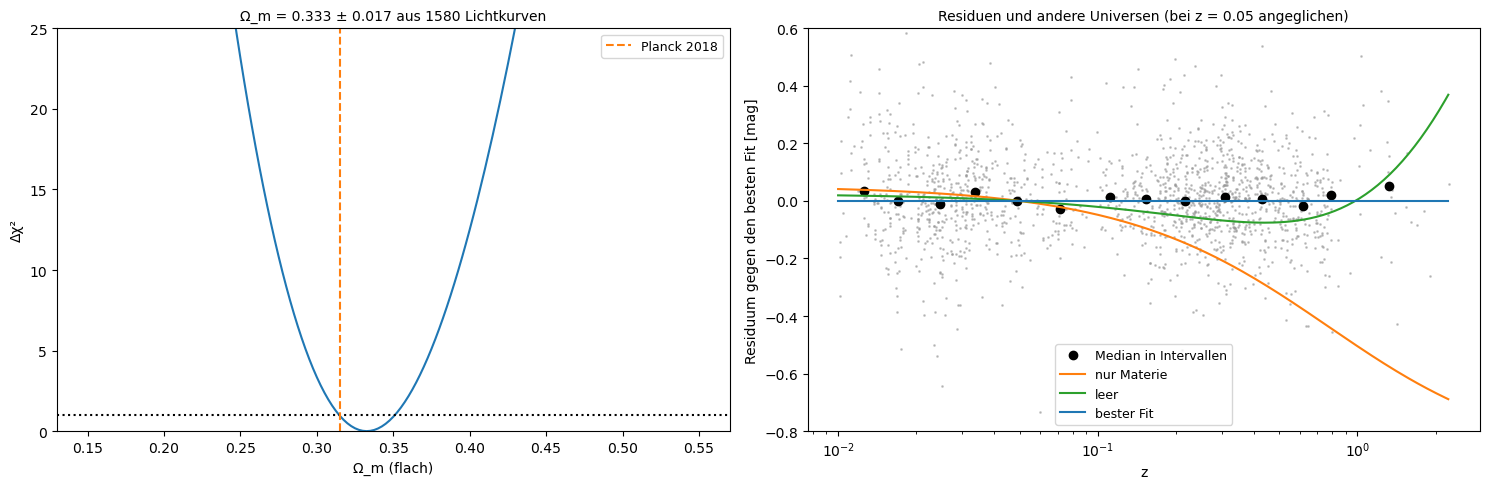

Ω_m = 0.3326 ± 0.0175 (Δχ² = 1), χ²_min = 1386.4 bei 1578 Freiheitsgraden; Ω_Λ = 0.667, q₀ = -0.501
Δχ² für Ω_m = 1 (nur Materie): 693


In [10]:
ic2 = np.where((SN["zHD"].values > Z_MIN_COSMO) & ~CAL)[0]
C2i = np.linalg.inv(subcov(ic2))
z2, zh2, m2 = SN["zHD"].values[ic2], SN["zHEL"].values[ic2], SN["m_b_corr"].values[ic2]
OM_GRID = np.linspace(0.15, 0.55, 161)
chi_om = np.array([offset_chi2(m2 - mu_model(z2, 70, om, zhel=zh2), C2i)[0] for om in OM_GRID])
fo = optimize.minimize_scalar(lambda om: offset_chi2(m2 - mu_model(z2, 70, om, zhel=zh2), C2i)[0], bounds=(0.1, 0.6), method="bounded")
OM_FIT = fo.x
inside = OM_GRID[chi_om - fo.fun < 1]
OM_ERR = (inside.max() - inside.min()) / 2
_, off_best = offset_chi2(m2 - mu_model(z2, 70, OM_FIT, zhel=zh2), C2i)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ax = axes[0]
ax.plot(OM_GRID, chi_om - fo.fun)
ax.axhline(1, color="k", ls=":")
ax.axvline(LIT["Om_Planck"][0], color="C1", ls="--", label="Planck 2018")
ax.set_ylim(0, 25)
ax.set_xlabel("Ω_m (flach)")
ax.set_ylabel("Δχ²")
ax.set_title(f"Ω_m = {OM_FIT:.3f} ± {OM_ERR:.3f} aus {len(ic2)} Lichtkurven", fontsize=10)
ax.legend(fontsize=9)
ax = axes[1]
res = m2 - off_best - mu_model(z2, 70, OM_FIT, zhel=zh2)
zb = np.logspace(-2, 0.35, 16)
k = np.digitize(z2, zb)
ax.plot(z2, res, ".", ms=2, color="0.6", alpha=0.5)
good = [j for j in range(1, len(zb)) if (k == j).sum() > 4]
ax.plot([np.median(z2[k == j]) for j in good], [np.median(res[k == j]) for j in good], "ko", label="Median in Intervallen")
ze = np.logspace(-2, 0.35, 200)
ref = mu_model(ze, 70, OM_FIT)
for (Om, Ol), col, lab in [((1.0, 0.0), "C1", "nur Materie"), ((0.0, 0.0), "C2", "leer"), ((OM_FIT, 1 - OM_FIT), "C0", "bester Fit")]:
    mm = mu_model(ze, 70, Om, Ol)
    ax.plot(ze, mm - ref - np.interp(0.05, ze, mm - ref), color=col, label=lab)
ax.set_xscale("log")
ax.set_ylim(-0.8, 0.6)
ax.set_xlabel("z")
ax.set_ylabel("Residuum gegen den besten Fit [mag]")
ax.set_title("Residuen und andere Universen (bei z = 0.05 angeglichen)", fontsize=10)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

print(f"Ω_m = {OM_FIT:.4f} ± {OM_ERR:.4f} (Δχ² = 1), χ²_min = {fo.fun:.1f} bei {len(ic2) - 2} Freiheitsgraden; "
      f"Ω_Λ = {1 - OM_FIT:.3f}, q₀ = {OM_FIT / 2 - (1 - OM_FIT):.3f}")
print(f"Δχ² für Ω_m = 1 (nur Materie): {offset_chi2(m2 - mu_model(z2, 70, 1.0, zhel=zh2), C2i)[0] - fo.fun:.0f}")

* Links Δχ² gegen Ω_m im flachen ΛCDM für 1580 Lichtkurven mit z > 0.01: Minimum bei Ω_m = 0.333 ± 0.018 (Δχ² = 1), χ² = 1386 bei 1578 Freiheitsgraden. Der Wert von Planck (0.315) liegt knapp innerhalb von 1σ.
* Rechts die Residuen gegen den besten Fit mit zwei anderen Universen, bei z = 0.05 angeglichen: nur Materie (orange) und leer (grün). Die Mediane folgen der blauen Linie bis z = 2.
* Zur Vorhersage: Die fernen Supernovae sind schwächer, als es ein Universum nur aus Materie erlaubt; Ω_m ist deshalb viel kleiner als 1, und Ω_m = 1 ist um Δχ² = 693 schlechter. Der Rest, Ω_Λ = 0.67, ist die kosmologische Konstante, und q₀ = −0.50: Die Expansion beschleunigt.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-9"></a>

##### *9. Beschleunigt die Expansion?*

Zeigen die Supernovae allein, ohne die Annahme eines flachen Universums, dass es eine kosmologische Konstante gibt? Vorher vorhersagen: Wo in der Ebene Ω_m gegen Ω_Λ liegen die erlaubten Werte, und schneiden sie die Linie Ω_Λ = 0?

Der Code rechnet χ² auf einem Gitter in Ω_m und Ω_Λ, mit Krümmung Ω_k = 1 − Ω_m − Ω_Λ, wieder über die additive Konstante minimiert. Eingezeichnet sind die Linie der flachen Universen, die Grenze zwischen Beschleunigung und Bremsung heute (q₀ = 0, also Ω_Λ = Ω_m/2) und der Wert von Planck. Das ist das Bild, mit dem Riess et al. (1998) und Perlmutter et al. (1999) die beschleunigte Expansion entdeckt haben.

**Hintergrund & Fachbegriffe:**
- **Kosmologische Konstante:** eine Energiedichte des leeren Raums, die bei Ausdehnung konstant bleibt und die Expansion beschleunigt; Ω_Λ ist ihr Anteil an der kritischen Dichte.
- **Krümmung:** In einem Universum mit Ω_m + Ω_Λ ≠ 1 ist der Raum gekrümmt; Lichtwege und damit Leuchtkraftentfernungen ändern sich (Theorie, Abschnitt 2).

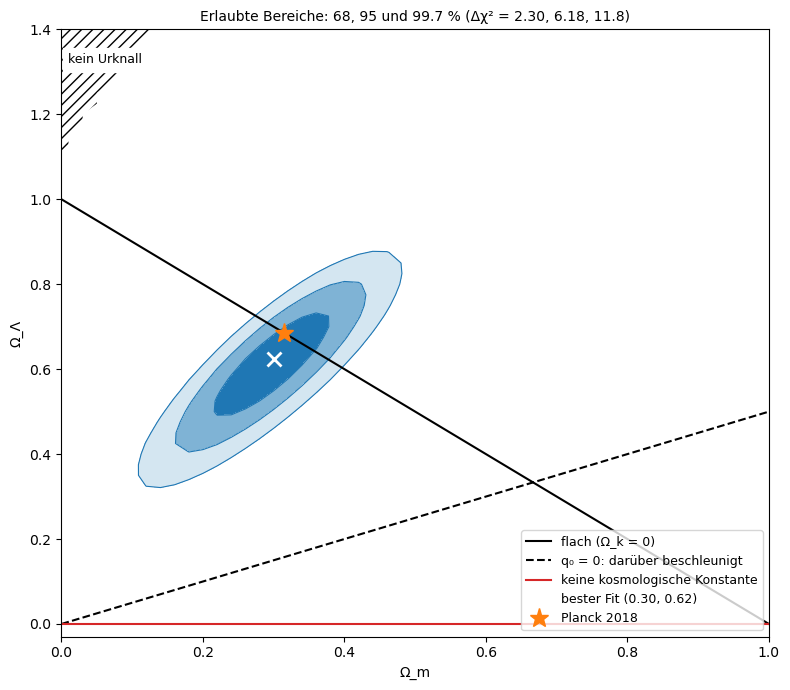

Bester Fit mit Krümmung: Ω_m = 0.30, Ω_Λ = 0.62, Ω_k = +0.07
Kleinstes Δχ² ohne kosmologische Konstante (Ω_Λ = 0): 49, entspricht 7 σ bei einem Parameter
Kleinstes Δχ² im gebremsten Bereich (q₀ > 0): 49; ausgeschlossene Gitterpunkte (kein Urknall): 45


In [11]:
OMg = np.linspace(0.0, 1.0, 51)
OLg = np.linspace(0.0, 1.4, 57)
z_chk = np.linspace(0, z2.max(), 400)


def physical(om, ol):
    # ein Urknall (E² > 0 bis zur fernsten Supernova) und positive Entfernungen; sonst ist das Modell ausgeschlossen
    ok = 1 - om - ol
    e2 = om * (1 + z_chk) ** 3 + ok * (1 + z_chk) ** 2 + ol
    return e2.min() > 0 and comoving(z2.max(), om, ol) > 0


VALID = np.array([[physical(om, ol) for om in OMg] for ol in OLg])
CHI = np.full(VALID.shape, np.inf)
with np.errstate(invalid="ignore", divide="ignore"):                  # in geschlossenen Modellen kann D_M zwischendurch negativ werden
    for a, ol in enumerate(OLg):
        for b, om in enumerate(OMg):
            if VALID[a, b]:
                c2 = offset_chi2(m2 - mu_model(z2, 70, om, ol, zhel=zh2), C2i)[0]
                if np.isfinite(c2):
                    CHI[a, b] = c2
                else:
                    VALID[a, b] = False
CHI -= CHI.min()
j, i = np.unravel_index(np.argmin(CHI), CHI.shape)
OM_NF, OL_NF = OMg[i], OLg[j]
fig, ax = plt.subplots(figsize=(8, 7))
CHI_PLOT = np.where(VALID, CHI, 1e4)
cs = ax.contourf(OMg, OLg, CHI_PLOT, levels=[0, 2.30, 6.18, 11.8], colors=["C0", "#7fb3d5", "#d4e6f1"])
ax.contour(OMg, OLg, CHI_PLOT, levels=[2.30, 6.18, 11.8], colors="C0", linewidths=0.8)
ax.contourf(OMg, OLg, (~VALID).astype(float), levels=[0.5, 1.5], colors="none", hatches=["///"])
ax.text(0.01, 1.32, "kein Urknall", fontsize=9, backgroundcolor="w")
ax.plot(OMg, 1 - OMg, "k-", label="flach (Ω_k = 0)")
ax.plot(OMg, OMg / 2, "k--", label="q₀ = 0: darüber beschleunigt")
ax.axhline(0, color="C3", lw=1.5, label="keine kosmologische Konstante")
ax.plot(OM_NF, OL_NF, "wx", ms=10, mew=2, label=f"bester Fit ({OM_NF:.2f}, {OL_NF:.2f})")
ax.plot(LIT["Om_Planck"][0], 1 - LIT["Om_Planck"][0], "C1*", ms=14, label="Planck 2018")
ax.set_xlabel("Ω_m")
ax.set_ylabel("Ω_Λ")
ax.set_title("Erlaubte Bereiche: 68, 95 und 99.7 % (Δχ² = 2.30, 6.18, 11.8)", fontsize=10)
ax.set_ylim(-0.03, 1.4)
ax.legend(fontsize=9, loc="lower right")
plt.tight_layout()
plt.show()

ol0 = CHI[0, VALID[0]].min()
acc = np.array([[ol > om / 2 for om in OMg] for ol in OLg])
print(f"Bester Fit mit Krümmung: Ω_m = {OM_NF:.2f}, Ω_Λ = {OL_NF:.2f}, Ω_k = {1 - OM_NF - OL_NF:+.2f}")
print(f"Kleinstes Δχ² ohne kosmologische Konstante (Ω_Λ = 0): {ol0:.0f}, entspricht {np.sqrt(ol0):.0f} σ bei einem Parameter")
print(f"Kleinstes Δχ² im gebremsten Bereich (q₀ > 0): {CHI[~acc & VALID].min():.0f}; ausgeschlossene Gitterpunkte (kein Urknall): {(~VALID).sum()}")

* Die Ebene Ω_m gegen Ω_Λ ohne die Annahme eines flachen Universums: Die erlaubten Bereiche (68, 95 und 99.7 %) liegen schräg, weil Supernovae vor allem die Kombination messen, die die Beschleunigung bestimmt. Der beste Wert ist Ω_m = 0.30, Ω_Λ = 0.62, also fast flach (Ω_k = +0.07); der Punkt von Planck liegt am Rand der 68-%-Fläche.
* Zur Vorhersage: Die Flächen liegen ganz über der gestrichelten Linie q₀ = 0 und weit über Ω_Λ = 0. Ohne kosmologische Konstante ist Δχ² mindestens 49, etwa 7σ: Die Supernovae allein zeigen die Beschleunigung, ohne Annahme über die Krümmung.
* Oben links (schraffiert) liegen 45 Gitterpunkte, in denen es keinen Urknall gäbe: Mit so viel Ω_Λ und so wenig Materie wäre das Universum in der Vergangenheit nie unendlich dicht gewesen.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-10"></a>

##### *10. Diagonale gegen volle Kovarianz*

Was ändert sich, wenn man die Korrelationen der Fehler vergisst? Vorher vorhersagen: Werden die Fehler von H₀ und Ω_m mit der Diagonale allein größer oder kleiner?

Der Code wiederholt die Fits von Schritt 7 und 8 mit drei Matrizen: der vollen Kovarianz, nur ihrer Diagonale und der Diagonale ohne die doppelten Lichtkurven (von jeder Supernova nur die Lichtkurve mit dem kleinsten Fehler). Verglichen werden Bestwerte und Fehler.

**Hintergrund & Fachbegriffe:**
- **Korrelierte Fehler im Fit:** Positive Korrelationen bedeuten, dass n Messungen weniger als n unabhängige Informationen enthalten; wer sie ignoriert, schätzt die Fehler zu klein. Gemeinsame systematische Verschiebungen können auch den Bestwert verschieben, wenn sie mit z zusammenhängen.
- **Doppelte Lichtkurven:** Dieselbe Supernova aus zwei Durchmusterungen hat Fehler, die zu 50 % und mehr korrelieren (Schritt 4); in der Diagonale zählt sie zweimal.

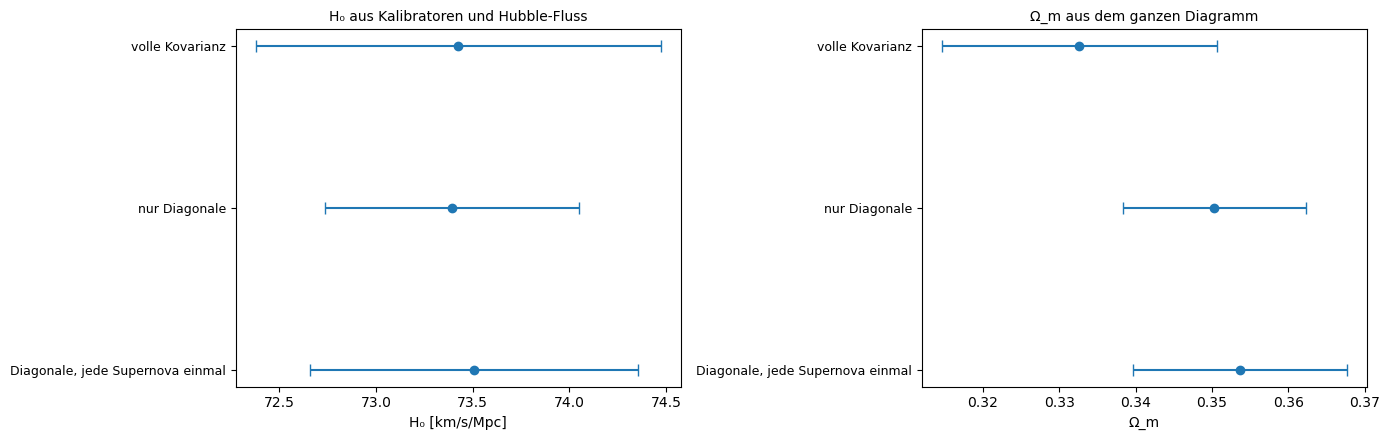

                          Matrix  Lichtkurven_H0      H0  H0_Fehler  Lichtkurven_Om     Om  Om_Fehler
                 volle Kovarianz             354 73.4251     1.0468            1580 0.3326     0.0180
                   nur Diagonale             354 73.3919     0.6567            1580 0.3503     0.0120
Diagonale, jede Supernova einmal             281 73.5079     0.8475            1466 0.3536     0.0140


In [12]:
def h0_fit(idx, diagonal):
    # M_B und H₀ wie in Schritt 7 für die Lichtkurven idx, mit voller Kovarianz oder nur ihrer Diagonale
    C_ = subcov(idx)
    Ci = np.linalg.inv(np.diag(np.diag(C_)) if diagonal else C_)
    zz_, zh_, mm_, ce_, ca_ = SN["zHD"].values[idx], SN["zHEL"].values[idx], SN["m_b_corr"].values[idx], SN["CEPH_DIST"].values[idx], CAL[idx]
    g = lambda p: (lambda r: r @ Ci @ r)(mm_ - p[0] - np.where(ca_, ce_, mu_model(zz_, p[1], OM_FIX, zhel=zh_)))
    f = optimize.minimize(g, [-19.25, 73.0], method="Nelder-Mead", options=dict(xatol=1e-7, fatol=1e-7))
    return f.x[1], np.sqrt(np.linalg.inv(hessian(g, f.x) / 2)[1, 1])


def om_fit(idx, diagonal):
    # Ω_m wie in Schritt 8 für die Lichtkurven idx
    C_ = subcov(idx)
    Ci = np.linalg.inv(np.diag(np.diag(C_)) if diagonal else C_)
    zz_, zh_, mm_ = SN["zHD"].values[idx], SN["zHEL"].values[idx], SN["m_b_corr"].values[idx]
    g = lambda om: offset_chi2(mm_ - mu_model(zz_, 70, om, zhel=zh_), Ci)[0]
    best = optimize.minimize_scalar(g, bounds=(0.1, 0.6), method="bounded")
    grid = np.linspace(best.x - 0.08, best.x + 0.08, 81)
    inside = grid[np.array([g(o) for o in grid]) - best.fun < 1]
    return best.x, (inside.max() - inside.min()) / 2


def once(idx):
    # von mehrfach beobachteten Supernovae nur die Lichtkurve mit dem kleinsten Fehler
    keep = SN.iloc[idx].sort_values("m_b_corr_err_DIAG").drop_duplicates("CID").index
    return np.sort(keep.values)


rows = []
for lab, ih0, iom, diag in [("volle Kovarianz", isel, ic2, False), ("nur Diagonale", isel, ic2, True),
                            ("Diagonale, jede Supernova einmal", once(isel), once(ic2), True)]:
    h, he = h0_fit(ih0, diag)
    o, oe = om_fit(iom, diag)
    rows.append(dict(Matrix=lab, Lichtkurven_H0=len(ih0), H0=h, H0_Fehler=he, Lichtkurven_Om=len(iom), Om=o, Om_Fehler=oe))
TAB = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (col, ecol, lab) in zip(axes, [("H0", "H0_Fehler", "H₀ [km/s/Mpc]"), ("Om", "Om_Fehler", "Ω_m")]):
    ax.errorbar(TAB[col], np.arange(len(TAB))[::-1], xerr=TAB[ecol], fmt="o", capsize=4)
    ax.set_yticks(np.arange(len(TAB))[::-1])
    ax.set_yticklabels(TAB["Matrix"], fontsize=9)
    ax.set_xlabel(lab)
axes[0].set_title("H₀ aus Kalibratoren und Hubble-Fluss", fontsize=10)
axes[1].set_title("Ω_m aus dem ganzen Diagramm", fontsize=10)
plt.tight_layout()
plt.show()
print(TAB.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

* Links H₀, rechts Ω_m mit drei Fehlermatrizen. Mit der vollen Kovarianz: 73.43 ± 1.05 und 0.333 ± 0.018. Nur die Diagonale: 73.39 ± 0.66 und 0.350 ± 0.012. Diagonale mit jeder Supernova einmal (281 und 1466 Lichtkurven): 73.51 ± 0.85 und 0.354 ± 0.014.
* Zur Vorhersage: Kleiner, und zwar falsch kleiner. Ohne Korrelationen schrumpft der Fehler von H₀ um 37 %, weil der systematische Teil der Kalibrierung, der alle Kalibratoren gemeinsam trifft, wegfällt. Bei Ω_m verschiebt sich zusätzlich der Bestwert um 0.017, fast 1σ: Gemeinsame Fehler, die mit z zusammenhängen (etwa die Kalibrierung der Filter einer Durchmusterung), ziehen den Fit, wenn man sie als unabhängig behandelt.
* Die Doppelungen allein erklären das nicht: Auch mit jeder Supernova einmal bleibt Ω_m bei 0.354. Der Unterschied steckt in den systematischen Termen der Kovarianz.

[↑ Zurück zur Landkarte](#landkarte)

#### **Eigene Messung gegen den Katalog**

<a id="exp-11"></a>

##### *11. H₀ gegen SH0ES und Planck: die Hubble-Spannung*

Wie stimmt das eigene H₀ mit der veröffentlichten Entfernungsleiter überein, und wie weit liegt es von dem Wert, den die Hintergrundstrahlung für ΛCDM vorhersagt? Vorher vorhersagen: Wie viele Standardabweichungen trennen 73 ± 1 von 67.4 ± 0.5?

Verglichen werden das eigene H₀ aus Schritt 7 mit Riess et al. (2022, die ganze Entfernungsleiter mit Cepheiden-Photometrie), Brout et al. (2022, dieselben Daten wie hier) und Planck 2018 (ΛCDM aus der Hintergrundstrahlung). Für den Abstand zweier unabhängiger Werte gilt (H₁ − H₂)/√(σ₁² + σ₂²). Rechts der Einfluss der Annahmen: Ω_m im Fit, die untere Grenze des Hubble-Flusses und die Rotverschiebung ohne Korrektur der Eigenbewegungen.

**Hintergrund & Fachbegriffe:**
- **Hubble-Spannung:** Die lokale Messung von H₀ mit der Entfernungsleiter liegt bei 73 km/s/Mpc, die aus der Hintergrundstrahlung mit ΛCDM bei 67 bis 68 km/s/Mpc; der Unterschied ist seit etwa 2019 größer als 4 σ.
- **Frühe gegen späte Messung:** Die Hintergrundstrahlung misst den Schallhorizont bei z ≈ 1100 und rechnet mit ΛCDM nach heute; die Entfernungsleiter misst heute direkt. Passen beide nicht, stimmt entweder eine Messung nicht oder das Modell.

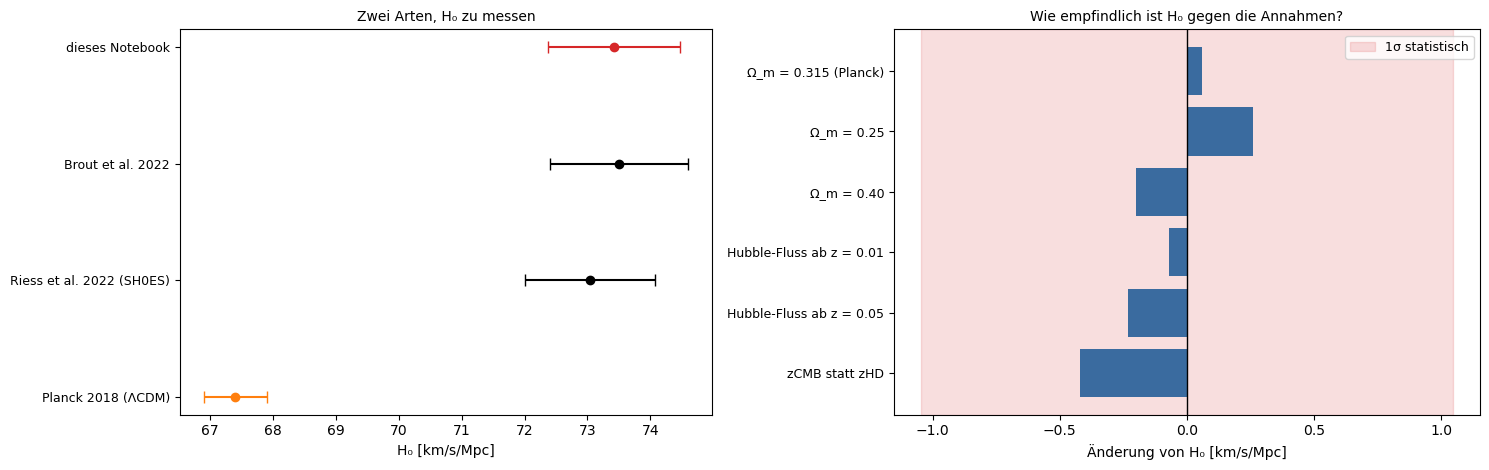

Eigenes H₀ = 73.43 ± 1.05: gegen Brout -0.0 σ, gegen SH0ES +0.3 σ, gegen Planck +5.2 σ
SH0ES gegen Planck: 4.9 σ
  Ω_m = 0.315 (Planck)        : H₀ = 73.48 (+0.06)
  Ω_m = 0.25                  : H₀ = 73.68 (+0.26)
  Ω_m = 0.40                  : H₀ = 73.22 (-0.20)
  Hubble-Fluss ab z = 0.01    : H₀ = 73.35 (-0.07)
  Hubble-Fluss ab z = 0.05    : H₀ = 73.19 (-0.23)
  zCMB statt zHD              : H₀ = 73.00 (-0.42)


In [13]:
def tension(a, b):
    return (a[0] - b[0]) / np.hypot(a[1], b[1])


OWN = (H0_J, H0_J_ERR)
checks = {}
for lab, kw in [("Ω_m = 0.315 (Planck)", dict(Om=0.315)), ("Ω_m = 0.25", dict(Om=0.25)), ("Ω_m = 0.40", dict(Om=0.40))]:
    checks[lab] = optimize.minimize(lambda p: chi2_joint(p, **kw), fit.x, method="Nelder-Mead", options=dict(xatol=1e-7)).x[1]
for lab, zlo, zcol in [("Hubble-Fluss ab z = 0.01", 0.01, "zHD"), ("Hubble-Fluss ab z = 0.05", 0.05, "zHD"), ("zCMB statt zHD", Z_HF[0], "zCMB")]:
    hf_alt = (~CAL) & (SN[zcol].values > zlo) & (SN[zcol].values < Z_HF[1])
    ia = np.where(CAL | hf_alt)[0]
    Ca = np.linalg.inv(subcov(ia))
    za, zha, ma, ca, isc = SN[zcol].values[ia], SN["zHEL"].values[ia], SN["m_b_corr"].values[ia], SN["CEPH_DIST"].values[ia], CAL[ia]
    g = lambda p: (lambda r: r @ Ca @ r)(ma - p[0] - np.where(isc, ca, mu_model(za, p[1], OM_FIX, zhel=zha)))
    checks[lab] = optimize.minimize(g, fit.x, method="Nelder-Mead", options=dict(xatol=1e-7)).x[1]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1, 1.1]})
ax = axes[0]
vals = [("dieses Notebook", OWN, "C3"), ("Brout et al. 2022", LIT["H0_Brout"], "k"), ("Riess et al. 2022 (SH0ES)", LIT["H0_SH0ES"], "k"),
        ("Planck 2018 (ΛCDM)", LIT["H0_Planck"], "C1")]
for i, (lab, (v, e), col) in enumerate(vals):
    ax.errorbar(v, -i, xerr=e, fmt="o", color=col, capsize=4)
ax.set_yticks([-i for i in range(len(vals))])
ax.set_yticklabels([v[0] for v in vals], fontsize=9)
ax.set_xlabel("H₀ [km/s/Mpc]")
ax.set_title("Zwei Arten, H₀ zu messen", fontsize=10)
ax = axes[1]
ax.barh(range(len(checks))[::-1], [v - H0_J for v in checks.values()], color="C0")
ax.set_yticks(range(len(checks))[::-1])
ax.set_yticklabels(list(checks), fontsize=9)
ax.axvline(0, color="k", lw=1)
ax.axvspan(-H0_J_ERR, H0_J_ERR, color="C3", alpha=0.15, label="1σ statistisch")
ax.set_xlabel("Änderung von H₀ [km/s/Mpc]")
ax.set_title("Wie empfindlich ist H₀ gegen die Annahmen?", fontsize=10)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

print(f"Eigenes H₀ = {H0_J:.2f} ± {H0_J_ERR:.2f}: gegen Brout {tension(OWN, LIT['H0_Brout']):+.1f} σ, "
      f"gegen SH0ES {tension(OWN, LIT['H0_SH0ES']):+.1f} σ, gegen Planck {tension(OWN, LIT['H0_Planck']):+.1f} σ")
print(f"SH0ES gegen Planck: {tension(LIT['H0_SH0ES'], LIT['H0_Planck']):.1f} σ")
for k_, v in checks.items():
    print(f"  {k_:28s}: H₀ = {v:.2f} ({v - H0_J:+.2f})")

* Links die vier Werte von H₀: dieses Notebook 73.43 ± 1.05, Brout et al. 73.5 ± 1.1 (dieselbe Rechnung, 0.0σ), Riess et al. 73.04 ± 1.04 (0.3σ), Planck 67.4 ± 0.5. Der Abstand zu Planck ist 5.2σ, der von SH0ES zu Planck 4.9σ.
* Rechts, wie stark H₀ an den Annahmen hängt: Ω_m zwischen 0.25 und 0.40 verschiebt H₀ um +0.26 bis −0.20, der Beginn des Hubble-Flusses bei 0.01 oder 0.05 um −0.07 und −0.23, die Rotverschiebung ohne Eigenbewegung (zCMB) um −0.42 km/s/Mpc. Alles bleibt innerhalb von 1σ und weit weg von 67.4.
* Zur Vorhersage: (73 − 67.4)/√(1² + 0.5²) = 5.0σ. Mit diesen Daten lässt sich die Spannung nicht wegrechnen; wenn ein Fehler steckt, dann in der Eichung von M_B durch die Cepheiden oder in der Annahme ΛCDM bei Planck.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-12"></a>

##### *12. Ω_m gegen Pantheon+ und Planck*

Passt der Materieanteil aus den Supernovae zu dem der Hintergrundstrahlung? Vorher vorhersagen: Ist der Unterschied bei Ω_m ebenfalls eine Spannung, oder stimmen die beiden hier überein?

Verglichen werden Ω_m aus Schritt 8 mit Brout et al. (2022, 0.334 ± 0.018, dieselben Daten) und Planck 2018 (0.315 ± 0.007). Dazu prüft der Code, wie Ω_m von der unteren Grenze in z abhängt: Nahe Supernovae tragen zu Ω_m kaum bei, aber sie legen den Nullpunkt fest, gegen den die fernen gemessen werden.

**Hintergrund & Fachbegriffe:**
- **Ω_m:** Anteil der Materie (dunkle und gewöhnliche) an der kritischen Dichte heute. Supernovae messen ihn über die Form des Hubble-Diagramms, die Hintergrundstrahlung über die Höhe der akustischen Peaks.
- **Unabhängige Messungen:** Wenn zwei Methoden mit ganz verschiedenen Fehlerquellen dasselbe Ω_m finden, ist ΛCDM in diesem Punkt bestätigt; die Spannung betrifft H₀.

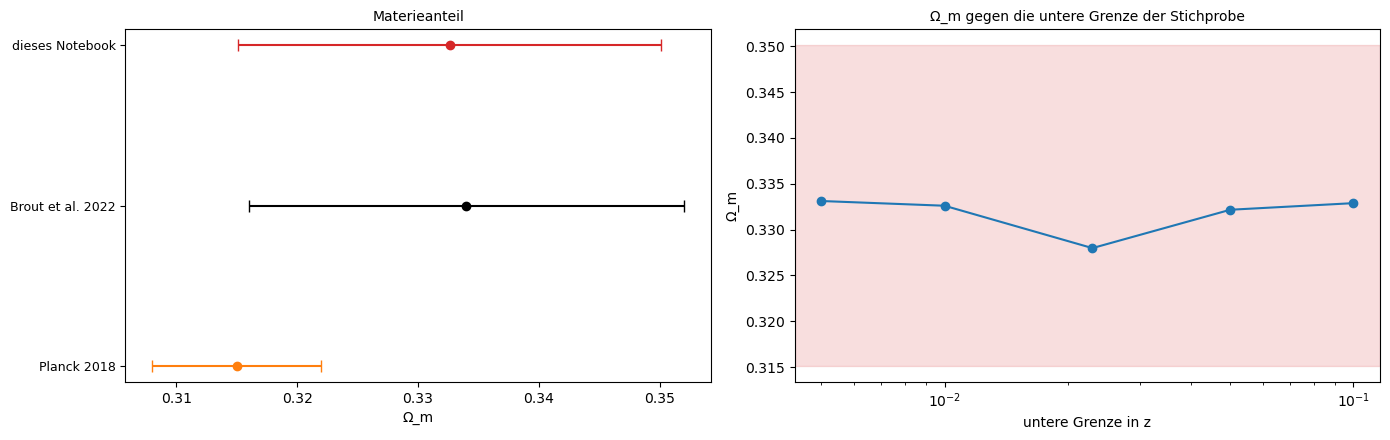

Ω_m = 0.3326 ± 0.0175: gegen Brout -0.06 σ, gegen Planck +0.93 σ
  z > 0.005 : Ω_m = 0.3331 (1619 Lichtkurven)
  z > 0.01  : Ω_m = 0.3326 (1580 Lichtkurven)
  z > 0.023 : Ω_m = 0.3280 (1371 Lichtkurven)
  z > 0.05  : Ω_m = 0.3322 (1056 Lichtkurven)
  z > 0.1   : Ω_m = 0.3329 (960 Lichtkurven)


In [14]:
om_checks = {}
for zlo in (0.005, 0.01, 0.023, 0.05, 0.1):
    ia = np.where((SN["zHD"].values > zlo) & ~CAL)[0]
    Ci_ = np.linalg.inv(subcov(ia))
    za, zha, ma = SN["zHD"].values[ia], SN["zHEL"].values[ia], SN["m_b_corr"].values[ia]
    om_checks[zlo] = (optimize.minimize_scalar(lambda om: offset_chi2(ma - mu_model(za, 70, om, zhel=zha), Ci_)[0],
                                               bounds=(0.1, 0.6), method="bounded").x, len(ia))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
ax = axes[0]
vals = [("dieses Notebook", (OM_FIT, OM_ERR), "C3"), ("Brout et al. 2022", LIT["Om_Brout"], "k"), ("Planck 2018", LIT["Om_Planck"], "C1")]
for i, (lab, (v, e), col) in enumerate(vals):
    ax.errorbar(v, -i, xerr=e, fmt="o", color=col, capsize=4)
ax.set_yticks([-i for i in range(len(vals))])
ax.set_yticklabels([v[0] for v in vals], fontsize=9)
ax.set_xlabel("Ω_m")
ax.set_title("Materieanteil", fontsize=10)
ax = axes[1]
ax.plot(list(om_checks), [v[0] for v in om_checks.values()], "o-")
ax.axhspan(OM_FIT - OM_ERR, OM_FIT + OM_ERR, color="C3", alpha=0.15)
ax.set_xscale("log")
ax.set_xlabel("untere Grenze in z")
ax.set_ylabel("Ω_m")
ax.set_title("Ω_m gegen die untere Grenze der Stichprobe", fontsize=10)
plt.tight_layout()
plt.show()

own = (OM_FIT, OM_ERR)
print(f"Ω_m = {OM_FIT:.4f} ± {OM_ERR:.4f}: gegen Brout {tension(own, LIT['Om_Brout']):+.2f} σ, gegen Planck {tension(own, LIT['Om_Planck']):+.2f} σ")
for zlo, (v, n_) in om_checks.items():
    print(f"  z > {zlo:<6}: Ω_m = {v:.4f} ({n_} Lichtkurven)")

* Links Ω_m: dieses Notebook 0.333 ± 0.018, Brout et al. 0.334 ± 0.018 (−0.06σ), Planck 0.315 ± 0.007 (0.9σ).
* Rechts Ω_m bei verschiedener unterer Grenze in z: 0.333, 0.333, 0.328, 0.332 und 0.333 für z > 0.005 bis 0.1, also stabil. Die nahen Supernovae tragen zu Ω_m kaum bei; sie legen nur den Nullpunkt fest, und der ist über die additive Konstante ohnehin frei.
* Zur Vorhersage: Keine Spannung. Supernovae und Hintergrundstrahlung messen mit ganz verschiedenen Methoden denselben Materieanteil; ΛCDM passt in Ω_m, aber nicht in H₀.

[↑ Zurück zur Landkarte](#landkarte)

#### **Ergebnis**

Beim Lauf vom 2026-11-08 (Pantheon+SH0ES DataRelease, Kovarianz STAT+SYS):

- **Daten:** 1701 Lichtkurven von 1543 Supernovae, z = 0.0012 bis 2.26; 77 Kalibrator-Lichtkurven von 43 Supernovae mit Cepheiden-Entfernung, 277 Lichtkurven im Hubble-Fluss (z = 0.023 bis 0.15). Lichtkurven derselben Supernova korrelieren im Median zu 0.41; gemeinsame Fehler machen den Mittelwert aller Lichtkurven 11 % unsicherer, als die Diagonale sagt.
- **Kalibrierung:** M_B = −19.249 ± 0.030 (Riess et al. 2022: −19.253 ± 0.027); Streuung der Kalibratoren 0.146 mag, ihre Wirtsgalaxien sind massereicher als die im Hubble-Fluss.
- **H₀:** Achsenabschnitt a_B = 0.7160 ± 0.0018 und damit H₀ = 73.49 ± 1.06; im gemeinsamen Fit mit voller Kovarianz **H₀ = 73.43 ± 1.05 km/s/Mpc**. Für Plancks 67.4 müssten Supernovae 0.19 mag heller sein, 6.2σ neben den Cepheiden.
- **Ω_m und Beschleunigung:** Flaches ΛCDM aus 1580 Lichtkurven: **Ω_m = 0.333 ± 0.018**, Ω_Λ = 0.67, q₀ = −0.50; ein Universum nur aus Materie ist um Δχ² = 693 schlechter. Mit freier Krümmung Ω_m = 0.30, Ω_Λ = 0.62; ohne kosmologische Konstante Δχ² ≥ 49 (etwa 7σ).
- **Kovarianz:** Nur mit der Diagonale wäre H₀ = 73.39 ± 0.66 (Fehler 37 % zu klein) und Ω_m = 0.350 ± 0.012 (Bestwert um fast 1σ verschoben).
- **Vergleich:** H₀ liegt 0.0σ von Brout et al. (73.5 ± 1.1), 0.3σ von SH0ES (73.04 ± 1.04) und **5.2σ** von Planck (67.4 ± 0.5); keine Annahme (Ω_m, Grenzen des Hubble-Flusses, Rotverschiebung) verschiebt es um mehr als 0.42 km/s/Mpc. Ω_m stimmt mit Brout (0.334) und mit Planck (0.315, 0.9σ) überein.

#### **Variationen**

Jeweils zuerst die Vorhersage notieren, dann den Code ändern und das Notebook neu ausführen:

1. **Ohne Beschleunigung im Achsenabschnitt:** `Q0, J0 = 0.0, 1.0` statt −0.55 in Schritt 6. *(Vorhersage: Die Korrektur ½(1 − q₀)z wird kleiner, a_B fällt von 0.7160 auf 0.7089 und H₀ aus dem Achsenabschnitt von 73.49 auf 72.30 km/s/Mpc, um 1.6 %. Schon bei z = 0.023 bis 0.15 ist die Beschleunigung nicht vernachlässigbar; der gemeinsame Fit in Schritt 7 rechnet mit ΛCDM und bleibt bei 73.43.)*
2. **Alle Supernovae im Hubble-Fluss:** In Schritt 7 `isel = np.where(CAL | ((SN["zHD"].values > 0.0233) & ~CAL))[0]`. *(Vorhersage: Statt 354 gehen 1442 Lichtkurven bis z = 2.3 in den Fit, aber H₀ wird nur wenig genauer: 73.66 ± 1.01 statt 73.43 ± 1.05. Der Fehler kommt aus M_B, also aus 43 Kalibratoren; mehr ferne Supernovae helfen nicht. Jetzt hängt H₀ allerdings stärker an Ω_m: mit 0.315 statt 0.334 wird es 73.82.)*
3. **Rotverschiebung ohne Eigenbewegungen für Ω_m:** In Schritt 8 `SN["zCMB"]` statt `SN["zHD"]` für `z2`. *(Vorhersage: Ω_m steigt von 0.333 auf 0.348, fast 1σ. Vermutlich haben die Eigenbewegungen bei 0.01 < z < 0.05 eine gemeinsame Richtung (der Fluss zu großen Massen in der Nachbarschaft); ohne Korrektur verbiegen sie das nahe Ende des Diagramms.)*
4. **Fehler doppelt so groß:** `COV = (COV + COV.T)` statt `/ 2`, also die ganze Kovarianz mal 2. *(Vorhersage: Alle Bestwerte bleiben gleich (M_B −19.249, H₀ 73.43, Ω_m 0.333), alle Fehler wachsen um √2 (H₀ ± 1.48, Ω_m ± 0.025), und χ² halbiert sich (150 statt 300 bei 352 Freiheitsgraden). Das χ² pro Freiheitsgrad prüft also, ob die Fehler stimmen: 0.85 im Original heißt, sie sind eher etwas zu groß.)*
5. **M_B ohne Korrelationen:** In Schritt 5 `np.diag(np.diag(subcov(ic)))` statt `subcov(ic)` in `gls`. *(Vorhersage: M_B = −19.245 ± 0.018 statt −19.249 ± 0.030; der Fehler wird 40 % zu klein, weil mehrfach beobachtete Kalibratoren und, vermutlich, gemeinsame Fehler der Cepheiden-Entfernungen als unabhängig zählen. H₀ aus Schritt 6 steigt auf 73.63.)*

#### **Wiederholung**

Erst selbst antworten, dann aufklappen.

<details><summary>1. Was misst die Hubble-Konstante, und was bedeuten 73 km/s/Mpc?</summary>

Wie schnell sich das Universum heute ausdehnt: Eine Galaxie in 1 Mpc Entfernung entfernt sich mit 73 km/s, eine in 100 Mpc mit 7300 km/s. Der Kehrwert, 1/H₀ ≈ 13.4 Milliarden Jahre, ist ungefähr das Alter des Universums.
</details>

<details><summary>2. Warum braucht man für H₀ sowohl nahe als auch ferne Supernovae?</summary>

Nahe Supernovae in Galaxien mit Cepheiden geben die absolute Helligkeit M_B, aber ihre Rotverschiebung ist von Eigenbewegungen verfälscht. Supernovae im Hubble-Fluss geben das Verhältnis von Helligkeit und Rotverschiebung, a_B, aber ohne M_B keine Entfernung. Erst zusammen folgt log₁₀ H₀ = 0.2 M_B + a_B + 5.
</details>

<details><summary>3. Warum beginnt der Hubble-Fluss erst bei z = 0.023?</summary>

Eine Eigenbewegung von 300 km/s ist bei cz = 3500 km/s ein Fehler von 8.6 % in der Entfernung, 0.18 mag, mehr als die Streuung einer Supernova. Bei z = 0.023 (cz ≈ 7000 km/s) sind es noch 4 %, und die Korrektur aus dem Geschwindigkeitsfeld macht den Rest klein.
</details>

<details><summary>4. Was standardisiert die Tripp-Formel?</summary>

Die Helligkeit im Maximum mit der Breite der Lichtkurve (breitere sind heller) und der Farbe (rötere sind schwächer, durch Staub und Eigenfarbe), dazu eine Stufe nach der Masse der Wirtsgalaxie. Danach streuen Supernovae um gut 0.1 mag statt 0.3 bis 0.4 mag.
</details>

<details><summary>5. Warum ist der Fehler von H₀ fast ganz der Fehler von M_B?</summary>

Weil der Achsenabschnitt a_B aus 277 Supernovae auf 0.4 % genau ist, M_B aus 43 Kalibratoren aber nur auf 0.03 mag, das sind 1.4 % in H₀. Mehr ferne Supernovae helfen deshalb kaum (Variation 2); man braucht mehr Galaxien mit Cepheiden und Supernovae.
</details>

<details><summary>6. Was zeigt die Fehlerellipse von M_B und H₀ mit Korrelation 0.96?</summary>

Dass die Daten fast nur eine Kombination der beiden festlegen: Ein helleres M_B und ein größeres H₀ beschreiben den Hubble-Fluss gleich gut. Erst die Kalibratoren schneiden die Ellipse ab.
</details>

<details><summary>7. Warum ist H₀ im Fit für Ω_m frei, und warum kann man es dort analytisch herausnehmen?</summary>

H₀ und M_B verschieben alle Helligkeiten um dieselbe Konstante; ohne Kalibratoren ist nur ihre Summe bestimmt. Eine additive Konstante lässt sich in χ² mit voller Kovarianz direkt ausrechnen, b = (1ᵀC⁻¹r)/(1ᵀC⁻¹1), übrig bleibt nur Ω_m.
</details>

<details><summary>8. Wie zeigen Supernovae, dass die Expansion beschleunigt?</summary>

Ferne Supernovae (z ≈ 0.5) sind schwächer als in einem Universum, das nur Materie enthält oder leer ist; das Licht hat einen längeren Weg hinter sich. Mit freier Krümmung liegen die erlaubten Werte ganz im Bereich q₀ < 0, und Ω_Λ = 0 ist mit etwa 7σ ausgeschlossen.
</details>

<details><summary>9. Was passiert, wenn man die Korrelationen der Fehler ignoriert?</summary>

Die Fehler werden zu klein (H₀ ± 0.66 statt ± 1.05), weil gemeinsame Fehler wie die Kalibrierung der Filter nicht mehr zählen; und wenn diese Fehler mit z zusammenhängen, wandert sogar der Bestwert (Ω_m 0.350 statt 0.333).
</details>

<details><summary>10. Wie viele σ trennen das eigene H₀ von Planck, und was bedeutet das?</summary>

(73.43 − 67.4)/√(1.05² + 0.5²) = 5.2σ. Bei unabhängigen, richtig geschätzten Fehlern ist ein solcher Unterschied durch Zufall praktisch ausgeschlossen; entweder steckt ein unbekannter systematischer Fehler in einer Messung, oder ΛCDM braucht eine Erweiterung.
</details>

<details><summary>11. Warum gibt es bei Ω_m keine Spannung?</summary>

Supernovae messen Ω_m über die Form des Hubble-Diagramms, unabhängig von M_B und H₀. Sie finden 0.333 ± 0.018, die Hintergrundstrahlung 0.315 ± 0.007, 0.9σ auseinander. ΛCDM passt also in der Form der Expansionsgeschichte, nur ihr heutiger Maßstab H₀ passt nicht.
</details>

<details><summary>12. Was sagt χ² = 300 bei 352 Freiheitsgraden?</summary>

χ² pro Freiheitsgrad ist 0.85; die Residuen sind etwas kleiner, als die Fehler erwarten lassen. Die Fehler sind also eher vorsichtig geschätzt. Bei Werten deutlich über 1 wären sie zu klein, und alle abgeleiteten Fehler zu optimistisch.
</details>

#### **Nächste Schritte**

So würde eine Analyse in der Forschung weitergehen:
- **Die Cepheiden selbst:** Die Eichung M_B hängt an der Photometrie der Cepheiden in überfüllten Feldern; mit dem James-Webb-Teleskop haben Riess et al. (2024) diese Messungen wiederholt und dasselbe gefunden. Andere Eichungen über die Spitze des Roten Riesenasts (TRGB) und Kohlenstoffsterne (JAGB) geben teils kleinere Werte (Freedman et al. 2024: um 70); ihr Vergleich ist der aktuelle Brennpunkt.
- **Unabhängige Wege zu H₀:** Gravitationswellen mit optischem Gegenstück (GW170817: 70 +12/−8), Zeitverzögerungen gelinster Quasare (H0LiCOW, TDCOSMO) und Maser in Galaxienkernen (NGC 4258) messen H₀ ohne die Leiter der Supernovae.
- **Das lokale Universum:** Liegt die Milchstraße in einer großen Unterdichte, wäre die Expansion lokal schneller; man prüft das mit H₀ in Rotverschiebungsschalen und mit der Verteilung der Galaxien.
- **Die andere Seite:** Aus der Hintergrundstrahlung allein, mit dem Schallhorizont, folgt 67.4; baryonische akustische Oszillationen (DESI) messen denselben Maßstab in der späten Zeit. Zusammen mit Supernovae zeigen sie Hinweise, dass die Dunkle Energie sich mit der Zeit ändert (w₀wₐCDM).
- **Bayessche Analyse:** Die Fits hier sind Maximum Likelihood mit Fehlern aus der Krümmung von χ²; in der Forschung zieht man mit MCMC (emcee, Cobaya) die ganze Verteilung, mit Prioren und gemeinsam mit anderen Daten.

#### **Referenzen**

- Ryden, B. (2017): *Introduction to Cosmology*, 2. Aufl., Cambridge (Kap. 4 und 5: Friedmann-Gleichung und Modelluniversen; Kap. 6: Entfernungsmaße und Standardkerzen).
- Hogg, D. W. (1999): *Distance measures in cosmology*, arXiv:astro-ph/9905116 (D_C, D_M, d_L mit Krümmung).
- Hubble, E. (1929): *A relation between distance and radial velocity among extra-galactic nebulae*, PNAS 15, 168.
- Freedman, W. L., Madore, B. F., Gibson, B. K. et al. (2001): *Final results from the Hubble Space Telescope Key Project to measure the Hubble constant*, ApJ 553, 47.
- Riess, A. G., Filippenko, A. V., Challis, P. et al. (1998): *Observational evidence from supernovae for an accelerating universe and a cosmological constant*, AJ 116, 1009.
- Perlmutter, S., Aldering, G., Goldhaber, G. et al. (1999): *Measurements of Ω and Λ from 42 high-redshift supernovae*, ApJ 517, 565.
- Tripp, R. (1998): *A two-parameter luminosity correction for Type Ia supernovae*, A&A 331, 815.
- Riess, A. G., Macri, L. M., Hoffmann, S. L. et al. (2016): *A 2.4% determination of the local value of the Hubble constant*, ApJ 826, 56 (Achsenabschnitt a_B und H₀ aus M_B).
- Scolnic, D., Brout, D., Carr, A. et al. (2022): *The Pantheon+ analysis: the full data set and light-curve release*, ApJ 938, 113.
- Brout, D., Scolnic, D., Popovic, B. et al. (2022): *The Pantheon+ analysis: cosmological constraints*, ApJ 938, 110 (Kovarianz, Ω_m = 0.334 ± 0.018, H₀ = 73.5 ± 1.1 zusammen mit SH0ES).
- Riess, A. G., Yuan, W., Macri, L. M. et al. (2022): *A comprehensive measurement of the local value of the Hubble constant with 1 km/s/Mpc uncertainty from the Hubble Space Telescope and the SH0ES team*, ApJL 934, L7.
- Planck Collaboration (2020): *Planck 2018 results. VI. Cosmological parameters*, A&A 641, A6.
- Riess, A. G., Anand, G. S., Yuan, W. et al. (2024): *JWST observations reject unrecognized crowding of Cepheid photometry as an explanation for the Hubble tension at 8σ confidence*, ApJL 962, L17.
- Freedman, W. L., Madore, B. F., Jang, I. S. et al. (2024): *Status report on the Chicago-Carnegie Hubble Program (CCHP)*, arXiv:2408.06153.